# 46 · Boreas-RT unseen-data transfer | FM .11 versus regression 2.26

**Frozen checkpoints, genuine four-sensor measurements, five physical topologies.** This notebook extends the evaluation protocol from `45_compare_newcollege_fm_vs_regression(4).ipynb` and uses the **actual Boreas loaders and odometry CSVs** from notebook `02_boreas_four_sensor_calibration_and_odometry.ipynb`.

| Short name | Physical sensors | Calibration keys |
|---|---|---|
| `2imu_velodyne` | DMU41 infilled + Aeva IMU + Velodyne | 3 |
| `2imu_aeva_lidar` | DMU41 infilled + Aeva IMU + Aeva LiDAR | 3 |
| `dmu_2lidars` | DMU41 infilled + Velodyne + Aeva LiDAR | 3 |
| `aevaimu_2lidars` | Aeva IMU + Velodyne + Aeva LiDAR | 3 |
| `2imu_2lidars` | All four physical sensors | 4 |

**Measurements entering the networks:** unmodified gyro/accel samples and independently registered LiDAR SE(3) increments. No ground-truth LiDAR poses are fed into the networks. **Nominal calibration references:** Boreas `calib/T_*.txt` files, which are not independently validated calibration ground truth. **Primary score:** SO(3) geodesic rotation error relative to these nominal matrices.

Evaluation consists of input integrity checks, paired one-window corrections, chronological **single-corrupted-sensor** rollouts, **all-sensors-corrupted** rollouts, summaries across topologies, and inference-time measurements. For clock offsets, only an optional *assumed-nominal* experiment is provided; there is no verified temporal calibration reference in the supplied files. The LiDAR-fault appendix from notebook 45 is intentionally omitted.

**Cost:** evaluation makes many frozen-model inference calls, especially for FM. For a fast first check, reduce `ROTATION_ANGLES_DEG`, `ONE_STEP_WINDOW_COUNT`, `ROLLOUT_NUM_WINDOWS`, or `ROLLOUT_AXES` below.

## 1. Paths, model checkpoints, physical topologies, and experiment controls

In [ ]:
from pathlib import Path
import os

RUN_NAME = "boreas_rt_fm11_vs_regression226_five_topologies"
SEQUENCE_ID = "boreas-2024-12-03-12-54"
BOREAS_DATA_ROOT = os.environ.get("BOREAS_DATA_ROOT")  # None uses BoreasDataset's OS-dependent default
REGRESSION_CHECKPOINT = Path("runs/kaist_pooled_calibration_paired_002.26_refined_tau_single_topology_light/best.pt")
FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt")
MODEL_LABELS = ("Regression 2.26", "FM .11")

IMU_IDS = ("dmu_infilled", "aeva")
LIDAR_IDS = ("velodyne", "aeva")
CALIBRATION_KEY_BY_SOURCE = {
    "dmu_infilled": "imu_dmu", "aeva_imu": "imu_aeva",
    "velodyne": "lidar_velodyne", "aeva_lidar": "lidar_aeva",
}
# Distinguish both physical sensors named 'aeva' by modality.
PHYSICAL_IMUS = {"imu_dmu": "dmu_infilled", "imu_aeva": "aeva"}
PHYSICAL_LIDARS = {"lidar_velodyne": "velodyne", "lidar_aeva": "aeva"}
ALL_CALIBRATION_KEYS = ("imu_dmu", "imu_aeva", "lidar_velodyne", "lidar_aeva")
TOPOLOGIES = {
    "2imu_velodyne": ("imu_dmu", "imu_aeva", "lidar_velodyne"),
    "2imu_aeva_lidar": ("imu_dmu", "imu_aeva", "lidar_aeva"),
    "dmu_2lidars": ("imu_dmu", "lidar_velodyne", "lidar_aeva"),
    "aevaimu_2lidars": ("imu_aeva", "lidar_velodyne", "lidar_aeva"),
    "2imu_2lidars": ALL_CALIBRATION_KEYS,
}
SENSOR_LABELS = {
    "imu_dmu": "DMU41 (infilled)", "imu_aeva": "Aeva IMU",
    "lidar_velodyne": "Velodyne LiDAR", "lidar_aeva": "Aeva LiDAR",
}

# All five topologies use the very same underlying physical time windows.
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_EVALUATION_DURATION_S = 180.0  # avoid loading an entire road trip by default; set None for available overlap
START_OFFSET_IN_OVERLAP_S = 0.0
MAX_WINDOWS = None
MAX_IMU_SAMPLES_PER_WINDOW = 700       # deterministic selection of measured samples, no interpolation
MAX_LIDAR_EDGES_PER_WINDOW = 200
MIN_IMU_SAMPLES_PER_WINDOW = 8
MIN_LIDAR_EDGES_PER_WINDOW = 2
MAX_NATIVE_IMU_GAP_S = 0.50

# No unverified time corrections are applied to the physical data by default.
IMU_TIMESTAMP_SHIFTS_S = {"dmu_infilled": 0.0, "aeva": 0.0}
LIDAR_TIMESTAMP_SHIFTS_S = {"velodyne": 0.0, "aeva": 0.0}
REFERENCE_TAU_S = {key: 0.0 for key in ALL_CALIBRATION_KEYS}  # ASSUMED, not verified true offsets

DEVICE_NAME = "cuda"  # falls back to CPU automatically when CUDA is absent
MODEL_DTYPE_NAME = "float32"
RANDOM_SEED = 12345
MODEL_DROPOUT = 0.0
FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
ROTATION_GAIN = 1.0
TAU_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None  # none reproduces notebook 45
ROTATION_CONVERGENCE_DEG = 5.0
STABLE_LAST_N_WINDOWS = 4

ROTATION_ANGLES_DEG = (0.0, 15.0, 45.0, 90.0, 130.0, 170.0, 179.0)
RUN_ONE_STEP = True
ONE_STEP_WINDOW_COUNT = 2
ONE_STEP_AXES = (0, 1, 2)
RUN_SINGLE_SENSOR_ROLLOUTS = True
ROLLOUT_START = 0
ROLLOUT_NUM_WINDOWS = 15        # None runs until available consecutive windows end
ROLLOUT_AXES = (0, 1, 2)       # (2,) is useful for a fast, yaw-only smoke test
RUN_ALL_SENSOR_ROLLOUTS = True
ALL_SENSOR_ANGLES_DEG = (0.0, 45.0, 90.0, 130.0, 170.0, 179.0)
ALL_SENSOR_DIRECTIONS = {"imu_dmu": (1, 0, 0), "imu_aeva": (0, 1, 0),
                         "lidar_velodyne": (0, 0, 1), "lidar_aeva": (1, 1, 1)}

# Experimental tau tests measure errors w.r.t. an *assumed nominal zero*, not true clocks.
RUN_ASSUMED_TAU_ROLLOUTS = False
ASSUMED_TAU_FAULTS_MS = (-150.0, 150.0)
RUN_ASSUMED_MIXED_ROLLOUTS = False
ASSUMED_MIXED_ROTVEC_DEG = (35.0, -45.0, 20.0)
ASSUMED_MIXED_TAU_MS = (-150.0, 150.0)

RUN_ODOMETRY_QUALITY_DIAGNOSTICS = True  # informational only; never used to change model inputs
POSE_MATCH_TOLERANCE_S = 0.15
POSE_INTERPOLATION_MAX_GAP_S = 0.40
MAX_ODOM_GT_DIAGNOSTIC_PAIRS = 300

SAVE_RESULTS = True
SHOW_PLOTS = True
PLOT_DPI = 150
INFERENCE_BENCHMARK_WARMUP = 2
INFERENCE_BENCHMARK_REPEATS = 3

## 2. Imports, paths, checkpoint and dataset preflight

In [2]:
import dataclasses
import inspect
import json
import sys
import time
from dataclasses import replace
from typing import get_type_hints

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.spatial.transform import Rotation as SciPyRotation
from IPython.display import display
from tqdm.auto import tqdm

ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "src" / "obscalib").is_dir() and (candidate / "src" / "boreas_dataset" / "dataset.py").is_file():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError("Start Jupyter within nn-obs-calib: expected src/obscalib and src/boreas_dataset")
sys.path.insert(0, str(ROOT / "src"))

from boreas_dataset.dataset import BoreasDataset
from boreas_dataset.calibration import validate_rigid_transform
from boreas_dataset.odometry import load_lidar_data_csv
from boreas_dataset.timing import relative_seconds, timestamps_to_ns
from obscalib.config import (CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig,
    PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig, TransformerConfig)
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
import obscalib.data.structures as structures
from obscalib.data.structures import WindowBatch
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

REGRESSION_CHECKPOINT = REGRESSION_CHECKPOINT if REGRESSION_CHECKPOINT.is_absolute() else ROOT / REGRESSION_CHECKPOINT
FM_CHECKPOINT = FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT / FM_CHECKPOINT
OUT = ROOT / "outputs" / "plots" / RUN_NAME
if SAVE_RESULTS:
    OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if DEVICE_NAME == "cuda" and torch.cuda.is_available() else "cpu")
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

sequence = BoreasDataset(BOREAS_DATA_ROOT).sequence(SEQUENCE_ID)
assert FM_INTEGRATION_STEPS >= 1 and FM_INTEGRATION_METHOD in ("euler", "midpoint")
missing = [str(p) for p in (REGRESSION_CHECKPOINT, FM_CHECKPOINT) if not p.is_file()]
for source in IMU_IDS:
    if source not in sequence.sensors["imu"]:
        missing.append(f"Boreas IMU {source}")
for source in LIDAR_IDS:
    if source not in sequence.sensors["lidar"]:
        missing.append(f"Boreas LiDAR {source}")
    cache_path = sequence.root / f"lidar_odometry_{source}.csv"
    if not cache_path.is_file():
        missing.append(str(cache_path))
for calibration_name in ("T_applanix_lidar", "T_applanix_dmu", "T_aeva_lidar", "T_imu_aeva"):
    if calibration_name not in sequence.calibrations:
        missing.append(f"calib/{calibration_name}.txt")
if missing:
    raise FileNotFoundError("All five topologies require the following missing inputs:\n" + "\n".join(missing))
print("Repository:", ROOT)
print("Boreas sequence:", sequence.root)
print("Inference device:", DEVICE)
print("Checkpoints:", REGRESSION_CHECKPOINT.name, "/", FM_CHECKPOINT.name)
print("Real-sensor topologies:", {name: len(keys) for name, keys in TOPOLOGIES.items()})

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": PLOT_DPI, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
ANGLE_COLORS = dict(zip(ROTATION_ANGLES_DEG, plt.get_cmap("viridis")(np.linspace(0.08, 0.92, len(ROTATION_ANGLES_DEG)))))
MODEL_STYLE = {MODEL_LABELS[0]: "--", MODEL_LABELS[1]: "-"}

def show_figure(fig, filename=None):
    fig.tight_layout()
    if SAVE_RESULTS and filename:
        fig.savefig(OUT / filename, dpi=PLOT_DPI, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
Boreas sequence: /mnt/d/Downloads/MobRobLab/BoreasDataset/boreas-2024-12-03-12-54
Inference device: cuda
Checkpoints: best.pt / best.pt
Real-sensor topologies: {'2imu_velodyne': 3, '2imu_aeva_lidar': 3, 'dmu_2lidars': 3, 'aevaimu_2lidars': 3, '2imu_2lidars': 4}


## 3. Independent LiDAR odometry and bounded physical time range

The caches must be the output of scan registration, not `sequence.lidar_poses(...)`. We keep scan timestamps as **integer nanoseconds** whenever metadata provides them. All five topologies are evaluated within the **intersection of both LiDAR recordings and both IMUs**.

velodyne    9,479 edges; median fitness=0.985, RMSE=0.164 m; uses_gt=False
aeva        9,859 edges; median fitness=0.980, RMSE=0.187 m; uses_gt=False
dmu_infilled   36,000 real samples; median rate=200.0 Hz
aeva           18,000 real samples; median rate=100.0 Hz
Common 4-sensor recording: 180.0 s (1733248461.991 ... 1733248641.978 UTC seconds)


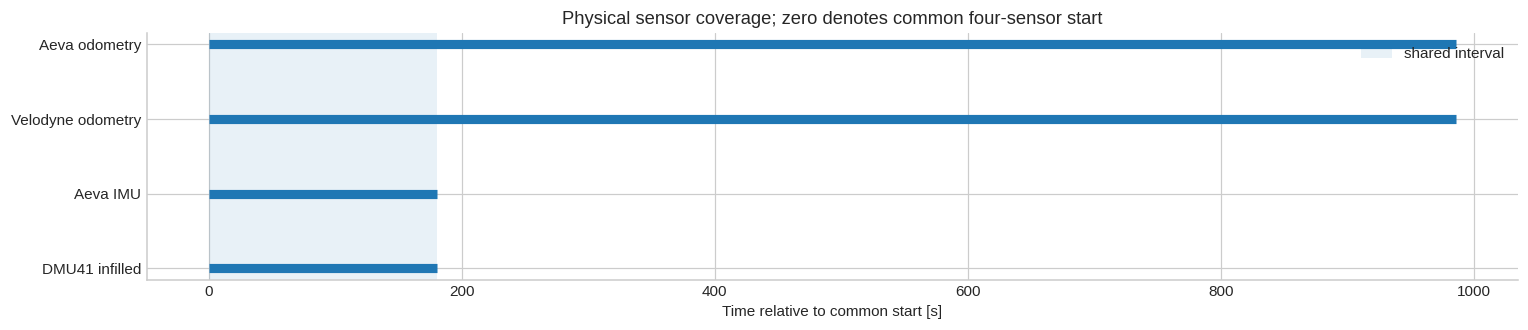

In [3]:
def odometry_scan_timestamps_ns(odom):
    """Use importer metadata when available; float CSV is a lower-precision fallback."""
    original = odom.metadata.get("scan_timestamps_ns")
    if isinstance(original, list) and len(original) == len(odom.scan_timestamps_s):
        ns = np.asarray(original, dtype=np.int64)
        if np.max(np.abs(ns.astype(np.float64) * 1e-9 - odom.scan_timestamps_s)) > 1e-3:
            raise ValueError("Stored scan_timestamps_ns disagree with CSV seconds")
    else:
        ns = np.rint(np.asarray(odom.scan_timestamps_s, dtype=np.float64) * 1e9).astype(np.int64)
        print("WARNING: exact scan_timestamps_ns unavailable; reconstructing from floating-point CSV seconds")
    if len(ns) < 3 or np.any(np.diff(ns) <= 0):
        raise ValueError("LiDAR scan timestamps must be strictly increasing with >=3 scans")
    return ns

odometries, odom_time_ns = {}, {}
for source in LIDAR_IDS:
    data = load_lidar_data_csv(sequence.root / f"lidar_odometry_{source}.csv")
    validate_rigid_transform(data.relative_poses_se3)
    if not data.metadata.get("independent_odometry", False) or data.metadata.get("uses_ground_truth", True):
        raise ValueError(f"{source}: expected independent scan-registration odometry (not GT-derived motion)")
    if len(data.relative_poses_se3) + 1 != len(data.scan_timestamps_s):
        raise ValueError(f"{source}: expected N relative transforms and N+1 scan timestamps")
    if data.metadata.get("relative_pose_convention") not in ("T_previous_current", "T_lidar_i_lidar_j"):
        raise ValueError(f"{source}: unsupported relative motion convention {data.metadata.get('relative_pose_convention')!r}")
    odometries[source] = data
    odom_time_ns[source] = odometry_scan_timestamps_ns(data) + round(LIDAR_TIMESTAMP_SHIFTS_S[source] * 1e9)
    print(f"{source:9s} {len(data.relative_poses_se3):>7,} edges; "
          f"median fitness={np.median(data.fitness):.3f}, RMSE={np.median(data.inlier_rmse):.3f} m; "
          f"uses_gt={data.metadata.get('uses_ground_truth')}")

lidar_overlap_start_ns = max(ts[0] for ts in odom_time_ns.values())
lidar_overlap_end_ns = min(ts[-1] for ts in odom_time_ns.values())
if lidar_overlap_end_ns - lidar_overlap_start_ns < 2 * WINDOW_DURATION_S * 1e9:
    raise ValueError("The two independent LiDAR caches have insufficient overlapping coverage")
request_start_ns = lidar_overlap_start_ns + round(START_OFFSET_IN_OVERLAP_S * 1e9)
request_end_ns = lidar_overlap_end_ns if MAX_EVALUATION_DURATION_S is None else min(
    lidar_overlap_end_ns, request_start_ns + round(MAX_EVALUATION_DURATION_S * 1e9))
if request_end_ns <= request_start_ns:
    raise ValueError("Empty requested interval: decrease START_OFFSET_IN_OVERLAP_S")

imus, imu_time_ns = {}, {}
for source in IMU_IDS:
    data = sequence.imu(source, time_start=request_start_ns * 1e-9, time_end=request_end_ns * 1e-9)
    if data.timestamps_ns is None or len(data.timestamps_ns) < MIN_IMU_SAMPLES_PER_WINDOW:
        raise ValueError(f"{source}: too few IMU samples in requested interval")
    imus[source] = data
    imu_time_ns[source] = np.asarray(data.timestamps_ns, dtype=np.int64) + round(IMU_TIMESTAMP_SHIFTS_S[source] * 1e9)
    print(f"{source:12s} {len(data.timestamps_ns):>8,} real samples; "
          f"median rate={data.frequency_hz:.1f} Hz")

COMMON_START_NS = max(request_start_ns, *(t[0] for t in odom_time_ns.values()), *(t[0] for t in imu_time_ns.values()))
COMMON_END_NS = min(request_end_ns, *(t[-1] for t in odom_time_ns.values()), *(t[-1] for t in imu_time_ns.values()))
if COMMON_END_NS - COMMON_START_NS < 2 * WINDOW_DURATION_S * 1e9:
    raise ValueError(f"Only {(COMMON_END_NS-COMMON_START_NS)*1e-9:.2f}s of common physical measurements")
print(f"Common 4-sensor recording: {(COMMON_END_NS-COMMON_START_NS)*1e-9:.1f} s "
      f"({COMMON_START_NS*1e-9:.3f} ... {COMMON_END_NS*1e-9:.3f} UTC seconds)")

fig, ax = plt.subplots(figsize=(14, 3.1))
for y, (name, ns) in enumerate([("DMU41 infilled", imu_time_ns["dmu_infilled"]),
                               ("Aeva IMU", imu_time_ns["aeva"]),
                               ("Velodyne odometry", odom_time_ns["velodyne"]),
                               ("Aeva odometry", odom_time_ns["aeva"])]):
    ax.hlines(y, (ns[0]-COMMON_START_NS)*1e-9, (ns[-1]-COMMON_START_NS)*1e-9, linewidth=6)
ax.axvspan(0, (COMMON_END_NS-COMMON_START_NS)*1e-9, alpha=.10, label="shared interval")
ax.set(yticks=range(4), yticklabels=["DMU41 infilled", "Aeva IMU", "Velodyne odometry", "Aeva odometry"],
       xlabel="Time relative to common start [s]", title="Physical sensor coverage; zero denotes common four-sensor start")
ax.legend()
show_figure(fig, "01_physical_sensor_coverage.png")

## 4. Physical rig calibration in one body frame

We exactly reproduce the chain used by Boreas notebook 02: `T_applanix_lidar` (Velodyne), `T_applanix_dmu`, `T_aeva_lidar` (Aeva LiDAR → Velodyne), and `T_imu_aeva` (Aeva LiDAR → Aeva IMU, interpreted by the existing loader/notebook). Hence `T_B_sensor` uses the **Applanix** body frame for all four sensors. No arbitrary common rotation is added.

imu_dmu            T_Applanix_sensor translation [m]: [ 0.    0.   -0.15]
imu_aeva           T_Applanix_sensor translation [m]: [-0.39883  0.33114 -0.12058]
lidar_velodyne     T_Applanix_sensor translation [m]: [0.   0.   0.13]
lidar_aeva         T_Applanix_sensor translation [m]: [-0.37615  0.31081 -0.08356]


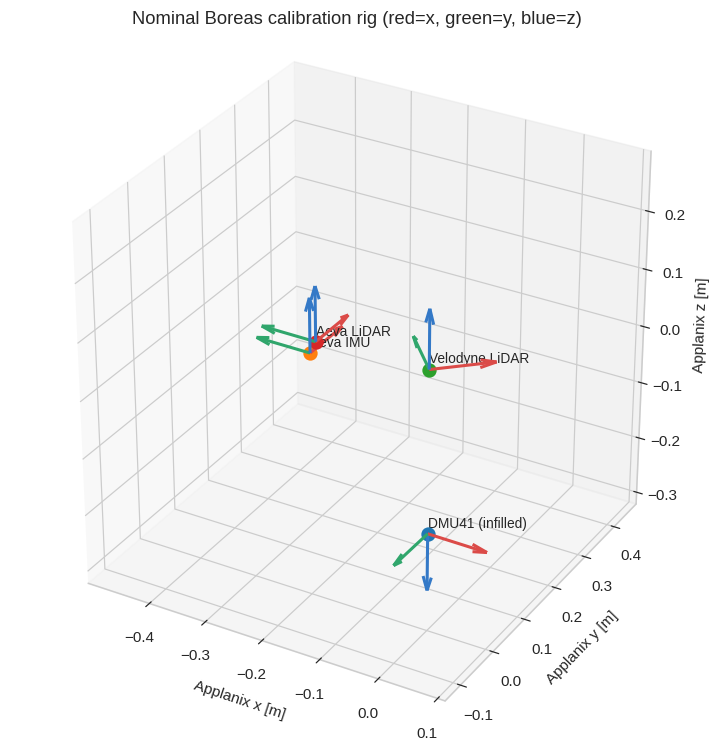

In [4]:
C = sequence.calibrations
T_B_sensor = {
    "imu_dmu": C["T_applanix_dmu"].copy(),
    "lidar_velodyne": C["T_applanix_lidar"].copy(),
}
T_B_sensor["lidar_aeva"] = T_B_sensor["lidar_velodyne"] @ np.linalg.inv(C["T_aeva_lidar"])
T_B_sensor["imu_aeva"] = T_B_sensor["lidar_aeva"] @ np.linalg.inv(C["T_imu_aeva"])
for key in ALL_CALIBRATION_KEYS:
    validate_rigid_transform(T_B_sensor[key])
    print(f"{key:18s} T_Applanix_sensor translation [m]: {np.round(T_B_sensor[key][:3,3], 5)}")
for source_a in ALL_CALIBRATION_KEYS:
    for source_b in ALL_CALIBRATION_KEYS:
        np.testing.assert_allclose(np.linalg.inv(T_B_sensor[source_a]) @ T_B_sensor[source_b],
                                   np.linalg.solve(T_B_sensor[source_a], T_B_sensor[source_b]), atol=1e-10)

fig = plt.figure(figsize=(12, 6.8))
ax = fig.add_subplot(111, projection="3d")
axis_colors = ("#db4b48", "#30a66c", "#3479c7")
origins = np.asarray([T_B_sensor[key][:3,3] for key in ALL_CALIBRATION_KEYS])
length = max(float(np.ptp(origins, axis=0).max()) * 0.25, 0.1)
for key in ALL_CALIBRATION_KEYS:
    T = T_B_sensor[key]
    p = T[:3, 3]
    ax.scatter(*p, s=70)
    ax.text(*(p + [0, 0, length * .12]), SENSOR_LABELS[key], fontsize=9)
    for k, color in enumerate(axis_colors):
        ax.quiver(*p, *(T[:3, k] * length), color=color, linewidth=2, arrow_length_ratio=.25)
span = max(float(np.ptp(origins, axis=0).max() + 2*length), .5)
center = (origins.max(axis=0) + origins.min(axis=0))*.5
ax.set(xlim=(center[0]-span/2,center[0]+span/2), ylim=(center[1]-span/2,center[1]+span/2),
       zlim=(center[2]-span/2,center[2]+span/2), xlabel="Applanix x [m]", ylabel="Applanix y [m]",
       zlabel="Applanix z [m]", title="Nominal Boreas calibration rig (red=x, green=y, blue=z)")
ax.set_box_aspect((1,1,1))
show_figure(fig, "02_boreas_calibration_rig.png")

## 5. Optional physical LiDAR-versus-reference diagnostic

This section checks scan matching quality against each sensor's `sequence.lidar_poses(source=...)`. **Only for reporting:** the network input remains the independent ICP edges, including Velodyne's observed drift/bias. The reference trajectory is never substituted for an ICP result.

In [5]:
quality_rows = []
if RUN_ODOMETRY_QUALITY_DIAGNOSTICS:
    for source, odom in odometries.items():
        gt = sequence.lidar_poses(source=source)
        times = odom_time_ns[source]
        valid = np.flatnonzero((times[:-1] >= gt.timestamps_ns[0]) & (times[1:] <= gt.timestamps_ns[-1]))
        selected = valid[np.linspace(0, len(valid)-1, min(len(valid), MAX_ODOM_GT_DIAGNOSTIC_PAIRS), dtype=int)] if len(valid) else []
        if len(selected) == 0:
            print(f"No ground truth overlapping {source} odometry; diagnostic skipped")
            continue
        query = np.unique(np.r_[times[np.asarray(selected)], times[np.asarray(selected)+1]])
        try:
            gt_matched = gt.match(query, tolerance_s=POSE_MATCH_TOLERANCE_S,
                                  interpolate=True, max_gap_s=POSE_INTERPOLATION_MAX_GAP_S)
        except ValueError as exc:
            print(f"GT diagnostic skipped for {source}: {exc}")
            continue
        idx0 = np.searchsorted(query, times[np.asarray(selected)])
        idx1 = np.searchsorted(query, times[np.asarray(selected)+1])
        delta_gt = np.linalg.solve(gt_matched[idx0], gt_matched[idx1])
        delta_odom = odom.relative_poses_se3[np.asarray(selected)]
        delta_error = np.linalg.solve(delta_gt, delta_odom)
        errors_rot = np.rad2deg(SciPyRotation.from_matrix(delta_error[:, :3, :3]).magnitude())
        errors_trans = np.linalg.norm(delta_error[:, :3,3],axis=1)
        quality_rows.append({"LiDAR":source,"evaluated edges":len(selected),
                             "median relative rotation error [deg]":np.median(errors_rot),
                             "median relative translation error [m]":np.median(errors_trans),
                             "median fitness":np.median(odom.fitness), "median ICP RMSE [m]":np.median(odom.inlier_rmse)})
    if quality_rows:
        display(pd.DataFrame(quality_rows).set_index("LiDAR").round(4))
    print("These reference errors are NOT weights or inputs to model inference.")

,evaluated edges,median relative rotation error [deg],median relative translation error [m],median fitness,median ICP RMSE [m]
LiDAR,,,,,
velodyne,300,0.0184,0.0343,0.9845,0.1636
aeva,300,0.0561,0.0202,0.9800,0.1870


These reference errors are NOT weights or inputs to model inference.


### 5.1. Independently integrated LiDAR drift, for context only

Like Boreas 02, integrate each original ICP increment (current → previous) by right multiplication and **anchor only the first pose** to the Applanix trajectory. This helps interpret why a model might prefer Aeva over Velodyne. The integrated paths and their GT errors are **not used as transformer inputs, weights, or correction targets**.

velodyne: final first-pose-anchored drift = 5.44 m, 3.28°
aeva: final first-pose-anchored drift = 30.45 m, 3.42°


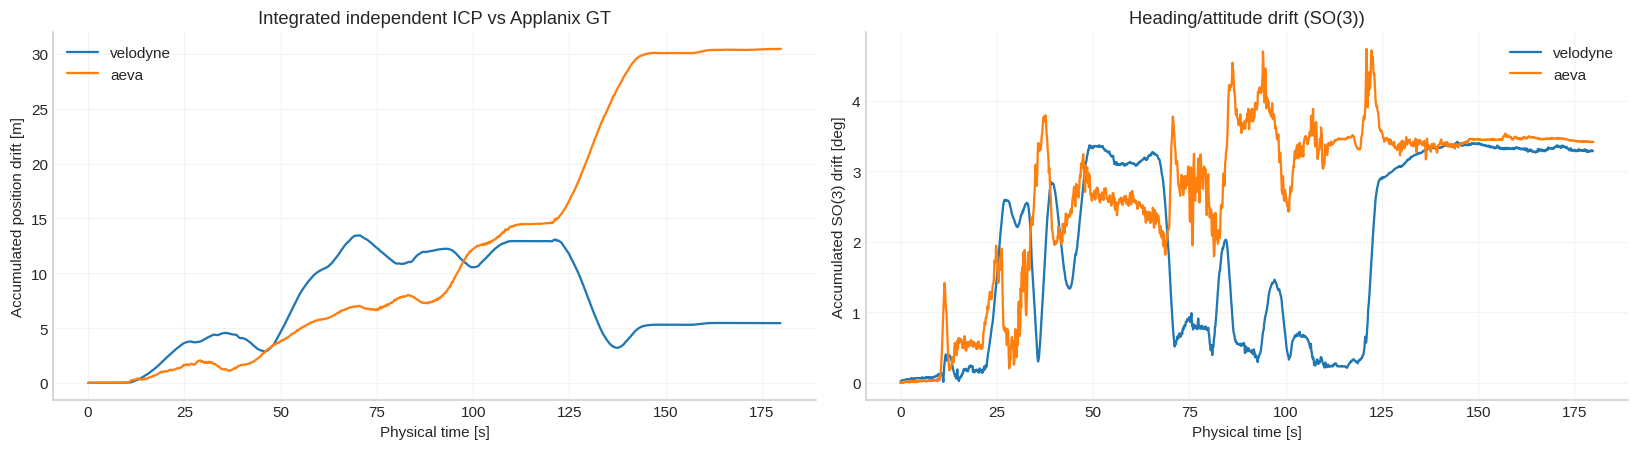

In [6]:
if RUN_ODOMETRY_QUALITY_DIAGNOSTICS:
    drift_results = {}
    for source in LIDAR_IDS:
        gt_trajectory = sequence.lidar_poses(source=source)
        ns = odom_time_ns[source]
        valid = np.flatnonzero((ns >= COMMON_START_NS) & (ns <= COMMON_END_NS) &
                               (ns >= gt_trajectory.timestamps_ns[0]) & (ns <= gt_trajectory.timestamps_ns[-1]))
        if len(valid) < 2:
            continue
        if np.any(np.diff(valid) != 1):
            raise ValueError(f"{source} GT-overlapping scan subset is not contiguous")
        begin, end = int(valid[0]), int(valid[-1])
        sample_ns = ns[begin:end+1]
        try:
            gt = gt_trajectory.match(sample_ns, tolerance_s=POSE_MATCH_TOLERANCE_S,
                                     interpolate=True, max_gap_s=POSE_INTERPOLATION_MAX_GAP_S)
        except ValueError as exc:
            print(f"{source}: could not match complete GT-aligned path: {exc}")
            continue
        # ICP convention: T_previous_current, so T_world_current = T_world_previous @ T_previous_current.
        est = np.repeat(np.eye(4)[None], len(sample_ns), axis=0)
        est[0] = gt[0]  # one-pose anchoring only
        for j, delta in enumerate(odometries[source].relative_poses_se3[begin:end], 1):
            est[j] = est[j-1] @ delta
        pose_error = np.linalg.solve(gt, est)
        drift_results[source] = dict(
            t=relative_seconds(sample_ns, int(sample_ns[0])),
            translation=np.linalg.norm(est[:,:3,3]-gt[:,:3,3],axis=1),
            rotation=np.rad2deg(SciPyRotation.from_matrix(pose_error[:,:3,:3]).magnitude()))
    if drift_results:
        fig,axs=plt.subplots(1,2,figsize=(15,4.2))
        for source,data in drift_results.items():
            axs[0].plot(data["t"],data["translation"],label=source)
            axs[1].plot(data["t"],data["rotation"],label=source)
            print(f"{source}: final first-pose-anchored drift = {data['translation'][-1]:.2f} m, "
                  f"{data['rotation'][-1]:.2f}°")
        axs[0].set(xlabel="Physical time [s]",ylabel="Accumulated position drift [m]",
                   title="Integrated independent ICP vs Applanix GT")
        axs[1].set(xlabel="Physical time [s]",ylabel="Accumulated SO(3) drift [deg]",
                   title="Heading/attitude drift (SO(3))")
        for ax in axs:
            ax.grid(alpha=.2)
            ax.legend()
        show_figure(fig,"02b_lidar_integrated_odom_drift_context_only.png")

## 6. Build authentic `WindowBatch` objects without KAIST dataset dependencies

The attached New College notebook used a KAIST sample to clone data classes. Here we find the *installed project's* dataclass types directly. Expected structures are `values`, local `timestamps`, boolean `sample_mask`, and optional LiDAR `interval_start_timestamps`; metadata carries modality, geometry type, and calibration key. **Only measured samples are selected.** Timestamp subtraction is performed in integer nanoseconds before conversion to float32 local seconds.

In [7]:
def dataclass_type_with_fields(required):
    required = set(required)
    candidates = []
    for cls in vars(structures).values():
        if isinstance(cls, type) and dataclasses.is_dataclass(cls) and required.issubset({f.name for f in dataclasses.fields(cls)}):
            if cls not in candidates:
                candidates.append(cls)
    # Prefer exact field matches to avoid accidentally choosing WindowBatch or a derived type.
    exact = [cls for cls in candidates if {f.name for f in dataclasses.fields(cls)} == required]
    matches = exact or candidates
    if len(matches) != 1:
        raise RuntimeError(f"Could not uniquely identify the project's dataclass with {required}: {matches}")
    return matches[0]

StreamType = dataclass_type_with_fields(("values", "timestamps", "sample_mask", "interval_start_timestamps"))
MetadataType = dataclass_type_with_fields(("measurement_type", "geometry_type", "calibration_key"))
metadata_hints = get_type_hints(MetadataType)
MeasurementType = metadata_hints["measurement_type"]
GeometryType = metadata_hints["geometry_type"]
for expected in ("IMU_GYROSCOPE", "IMU_ACCELEROMETER", "LIDAR_POSE"):
    if not hasattr(MeasurementType, expected):
        raise RuntimeError(f"Installed measurement type {MeasurementType} has no {expected}")
for expected in ("VECTOR", "SE3"):
    if not hasattr(GeometryType, expected):
        raise RuntimeError(f"Installed geometry type {GeometryType} has no {expected}")
print("Stream class:", StreamType, "; metadata class:", MetadataType)

STREAM_SPECS = {
    "gyro_dmu": ("imu_dmu", MeasurementType.IMU_GYROSCOPE, GeometryType.VECTOR),
    "accel_dmu": ("imu_dmu", MeasurementType.IMU_ACCELEROMETER, GeometryType.VECTOR),
    "gyro_aeva": ("imu_aeva", MeasurementType.IMU_GYROSCOPE, GeometryType.VECTOR),
    "accel_aeva": ("imu_aeva", MeasurementType.IMU_ACCELEROMETER, GeometryType.VECTOR),
    "lidar_velodyne": ("lidar_velodyne", MeasurementType.LIDAR_POSE, GeometryType.SE3),
    "lidar_aeva": ("lidar_aeva", MeasurementType.LIDAR_POSE, GeometryType.SE3),
}
STREAM_METADATA = {name: MetadataType(measurement_type=measurement_type,
    geometry_type=geometry_type, calibration_key=key)
    for name, (key, measurement_type, geometry_type) in STREAM_SPECS.items()}


def select_measured_samples(indices, maximum):
    """Deterministic uniform-index selection; preserves actual samples and times."""
    indices = np.asarray(indices, dtype=np.int64)
    if len(indices) <= maximum:
        return indices
    return indices[np.unique(np.linspace(0, len(indices)-1, maximum, dtype=int))]


def create_stream(values, end_ns, t0_ns, *, start_ns=None):
    """One batch, native sensor values; LiDAR edges have explicit interval starts."""
    values_tensor = torch.as_tensor(np.asarray(values), dtype=MODEL_DTYPE).unsqueeze(0)
    end = torch.as_tensor(relative_seconds(np.asarray(end_ns, dtype=np.int64), int(t0_ns)), dtype=torch.float32).unsqueeze(0)
    start = None if start_ns is None else torch.as_tensor(
        relative_seconds(np.asarray(start_ns, dtype=np.int64), int(t0_ns)), dtype=torch.float32).unsqueeze(0)
    return StreamType(values=values_tensor, timestamps=end,
                      sample_mask=torch.ones((1, values_tensor.shape[1]), dtype=torch.bool),
                      interval_start_timestamps=start)


def reference_states_on_device(device="cpu"):
    return {key: CalibrationState(
        transform=torch.as_tensor(T_B_sensor[key], dtype=MODEL_DTYPE, device=device).unsqueeze(0),
        time_offset=torch.tensor([[REFERENCE_TAU_S[key]]], dtype=MODEL_DTYPE, device=device))
        for key in ALL_CALIBRATION_KEYS}

WINDOW_NS = round(WINDOW_DURATION_S * 1e9)
STRIDE_NS = round(WINDOW_STRIDE_S * 1e9)
if WINDOW_NS < 1 or STRIDE_NS < 1:
    raise ValueError("Window duration and stride must be positive")
window_starts_ns = np.arange(COMMON_START_NS, COMMON_END_NS - WINDOW_NS + 1, STRIDE_NS, dtype=np.int64)
if MAX_WINDOWS is not None:
    window_starts_ns = window_starts_ns[:MAX_WINDOWS]

# Precompute index spans for each candidate window, including two independent ICP edge sequences.
window_records = []
for start_ns in window_starts_ns:
    end_ns = int(start_ns) + WINDOW_NS
    imu_slices = {}
    edge_slices = {}
    accepted = True
    for source in IMU_IDS:
        t = imu_time_ns[source]
        selected = np.flatnonzero((t >= start_ns) & (t < end_ns))
        if len(selected) < MIN_IMU_SAMPLES_PER_WINDOW:
            accepted = False
            break
        native_gaps = np.diff(t[selected]) * 1e-9
        if len(native_gaps) and np.max(native_gaps) > MAX_NATIVE_IMU_GAP_S:
            accepted = False
            break
        imu_slices[source] = select_measured_samples(selected, MAX_IMU_SAMPLES_PER_WINDOW)
    if not accepted:
        continue
    for source in LIDAR_IDS:
        t = odom_time_ns[source]
        selected = np.flatnonzero((t[:-1] >= start_ns) & (t[1:] <= end_ns))
        if not MIN_LIDAR_EDGES_PER_WINDOW <= len(selected) <= MAX_LIDAR_EDGES_PER_WINDOW:
            accepted = False
            break
        edge_slices[source] = selected
    if accepted:
        window_records.append((int(start_ns), imu_slices, edge_slices))
if not window_records:
    raise RuntimeError("No valid four-sensor windows: inspect timestamp units, common overlap and MAX_NATIVE_IMU_GAP_S")

class BoreasFourSensorDataset:
    """Fresh time-local `WindowBatch` objects, no GT in any measurement stream."""
    calibration_keys = ALL_CALIBRATION_KEYS
    def __len__(self):
        return len(window_records)
    def __getitem__(self, index):
        t0, imu_slices, edge_slices = window_records[index]
        streams = {}
        for source, prefix in (("dmu_infilled", "dmu"), ("aeva", "aeva")):
            i = imu_slices[source]
            data = imus[source]
            streams[f"gyro_{prefix}"] = create_stream(data.data_gyr[i], imu_time_ns[source][i], t0)
            streams[f"accel_{prefix}"] = create_stream(data.data_acc[i], imu_time_ns[source][i], t0)
        for source in LIDAR_IDS:
            i = edge_slices[source]
            streams[f"lidar_{source}"] = create_stream(odometries[source].relative_poses_se3[i],
                odom_time_ns[source][i+1], t0, start_ns=odom_time_ns[source][i])
        return WindowBatch(streams=streams, metadata=dict(STREAM_METADATA),
                           current_calibration=reference_states_on_device(), targets=None,
                           dataset_indices=torch.tensor([index], dtype=torch.long))

boreas_windows = BoreasFourSensorDataset()
print(f"Valid windows: {len(boreas_windows)} / {len(window_starts_ns)}; "
      f"first={window_records[0][0]*1e-9:.3f} UTC, last={window_records[-1][0]*1e-9:.3f} UTC")
for index in sorted({0,len(boreas_windows)//2,len(boreas_windows)-1}):
    window = boreas_windows[index]
    for stream_name, stream in window.streams.items():
        assert bool(stream.sample_mask.all()) and bool(torch.isfinite(stream.values).all())
        assert bool(torch.isfinite(stream.timestamps).all())
        assert float(stream.timestamps.min()) >= -1e-5
        assert float(stream.timestamps.max()) <= WINDOW_DURATION_S + 1e-4
        if stream_name.startswith("lidar_"):
            assert stream.values.shape[2:] == (4,4)
            assert stream.interval_start_timestamps is not None
            assert bool((stream.timestamps > stream.interval_start_timestamps).all())
    print("Window",index, ":", {key:tuple(s.values.shape) for key,s in window.streams.items()})

Stream class: <class 'obscalib.data.structures.SensorStreamBatch'> ; metadata class: <class 'obscalib.data.structures.SensorMetadata'>
Valid windows: 35 / 35; first=1733248461.991 UTC, last=1733248631.991 UTC
Window 0 : {'gyro_dmu': (1, 700, 3), 'accel_dmu': (1, 700, 3), 'gyro_aeva': (1, 500, 3), 'accel_aeva': (1, 500, 3), 'lidar_velodyne': (1, 47, 4, 4), 'lidar_aeva': (1, 49, 4, 4)}
Window 17 : {'gyro_dmu': (1, 700, 3), 'accel_dmu': (1, 700, 3), 'gyro_aeva': (1, 500, 3), 'accel_aeva': (1, 500, 3), 'lidar_velodyne': (1, 47, 4, 4), 'lidar_aeva': (1, 49, 4, 4)}
Window 34 : {'gyro_dmu': (1, 700, 3), 'accel_dmu': (1, 700, 3), 'gyro_aeva': (1, 500, 3), 'accel_aeva': (1, 500, 3), 'lidar_velodyne': (1, 46, 4, 4), 'lidar_aeva': (1, 49, 4, 4)}


## 7. Shared topology routing and sensor counts

For each topology the **same** physical four-sensor window is filtered to the participating sensors. Each gyro and accel pair shares one IMU calibration key; each LiDAR gets one independent calibration key. This generalizes notebook 45's `tokenize_candidate`, which had hard-coded exactly three calibration keys.

In [8]:
def make_topology_window(full_window, topology):
    keys = TOPOLOGIES[topology]
    streams = {name: data for name, data in full_window.streams.items()
               if STREAM_SPECS[name][0] in keys}
    metadata = {name: full_window.metadata[name] for name in streams}
    states = {key: full_window.current_calibration[key] for key in keys}
    expected_streams = sum(2 if key.startswith("imu_") else 1 for key in keys)
    assert len(streams) == expected_streams
    return replace(full_window, streams=streams, metadata=metadata, current_calibration=states)


def to_device(window):
    return window_batch_to(window, DEVICE, dtype=MODEL_DTYPE)

first_full = boreas_windows[0]
for topology, keys in TOPOLOGIES.items():
    w = make_topology_window(first_full, topology)
    assert tuple(w.current_calibration) == keys
    assert {m.calibration_key for m in w.metadata.values()} == set(keys)
    for imu_key in keys:
        if imu_key.startswith("imu_"):
            assert len([s for s, m in w.metadata.items() if m.calibration_key == imu_key]) == 2
    print(f"{topology:18s} calibration keys={len(keys)}, input streams={len(w.streams)} : {keys}")

2imu_velodyne      calibration keys=3, input streams=5 : ('imu_dmu', 'imu_aeva', 'lidar_velodyne')
2imu_aeva_lidar    calibration keys=3, input streams=5 : ('imu_dmu', 'imu_aeva', 'lidar_aeva')
dmu_2lidars        calibration keys=3, input streams=4 : ('imu_dmu', 'lidar_velodyne', 'lidar_aeva')
aevaimu_2lidars    calibration keys=3, input streams=4 : ('imu_aeva', 'lidar_velodyne', 'lidar_aeva')
2imu_2lidars       calibration keys=4, input streams=6 : ('imu_dmu', 'imu_aeva', 'lidar_velodyne', 'lidar_aeva')


## 8. Load the *same frozen* regression 2.26 and FM .11 checkpoints used on New College

In [9]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12,
                                  dim_feedforward=512, dropout=MODEL_DROPOUT,
                                  num_summary_tokens=1, activation="gelu"),
    mlp=MLPConfig(hidden_dims=(256,128), output_dim=128, activation="gelu", dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128,64),
                                     activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)
regression_model = PooledCalibrationModel(model_config).to(DEVICE, dtype=MODEL_DTYPE)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=MODEL_DTYPE)
regression_metadata = load_training_checkpoint(REGRESSION_CHECKPOINT, model=regression_model,
    map_location=DEVICE, restore_rng_state=False)
fm_metadata = load_training_checkpoint(FM_CHECKPOINT, model=fm_model,
    map_location=DEVICE, restore_rng_state=False)
regression_model.eval().requires_grad_(False)
fm_model.eval().requires_grad_(False)
MODELS = {MODEL_LABELS[0]: regression_model, MODEL_LABELS[1]: fm_model}
geometry_processor = GeometryProcessor()


def tokenize_candidate(window, states):
    keys = tuple(window.current_calibration)
    if set(keys) != set(states):
        raise ValueError(f"Topology/current-calibration mismatch: {keys} vs {tuple(states)}")
    canonical = geometry_processor(window.streams, window.metadata, states)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise ValueError(f"Unexpected tokens for {keys}: {tokens.x.shape}, {tokens.calibration_keys}")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    return tokens, context


@torch.inference_mode()
def predict_from_tokens(model, tokens, context):
    if isinstance(model, PooledCalibrationFlowModel):
        result = model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    else:
        result = model(tokens, context)
    if set(result.predictions) != set(tokens.calibration_keys):
        raise RuntimeError(f"Predictions returned {tuple(result.predictions)}, expected {tuple(tokens.calibration_keys)}")
    for key, pred in result.predictions.items():
        if pred.delta_xi.shape != (tokens.x.shape[0],6) or pred.delta_tau.shape != (tokens.x.shape[0],1):
            raise ValueError(f"Unexpected {key} update shapes: {pred.delta_xi.shape}, {pred.delta_tau.shape}")
        if not torch.isfinite(pred.delta_xi).all() or not torch.isfinite(pred.delta_tau).all():
            raise FloatingPointError(f"Nonfinite {key} calibration correction")
    return result


@torch.inference_mode()
def calibration_forward(window, states, model):
    tokens, context = tokenize_candidate(window, states)
    return predict_from_tokens(model, tokens, context)

for topology in TOPOLOGIES:
    example = to_device(make_topology_window(first_full, topology))
    tokens, context = tokenize_candidate(example, example.current_calibration)
    print(f"{topology:18s} tokens={tuple(tokens.x.shape)} calibration_keys={tuple(tokens.calibration_keys)}")
    for label, model in MODELS.items():
        output = predict_from_tokens(model, tokens, context)
        print(f"  {label}: output keys={tuple(output.predictions)}")
print("Frozen checkpoint epochs:", regression_metadata.get("epoch"), fm_metadata.get("epoch"))
print("Parameter counts:", {label:sum(p.numel() for p in model.parameters()) for label,model in MODELS.items()})

2imu_velodyne      tokens=(1, 2447, 8) calibration_keys=('imu_dmu', 'imu_aeva', 'lidar_velodyne')


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


  Regression 2.26: output keys=('imu_dmu', 'imu_aeva', 'lidar_velodyne')
  FM .11: output keys=('imu_dmu', 'imu_aeva', 'lidar_velodyne')
2imu_aeva_lidar    tokens=(1, 2449, 8) calibration_keys=('imu_dmu', 'imu_aeva', 'lidar_aeva')
  Regression 2.26: output keys=('imu_dmu', 'imu_aeva', 'lidar_aeva')
  FM .11: output keys=('imu_dmu', 'imu_aeva', 'lidar_aeva')
dmu_2lidars        tokens=(1, 1496, 8) calibration_keys=('imu_dmu', 'lidar_velodyne', 'lidar_aeva')
  Regression 2.26: output keys=('imu_dmu', 'lidar_velodyne', 'lidar_aeva')
  FM .11: output keys=('imu_dmu', 'lidar_velodyne', 'lidar_aeva')
aevaimu_2lidars    tokens=(1, 1096, 8) calibration_keys=('imu_aeva', 'lidar_velodyne', 'lidar_aeva')
  Regression 2.26: output keys=('imu_aeva', 'lidar_velodyne', 'lidar_aeva')
  FM .11: output keys=('imu_aeva', 'lidar_velodyne', 'lidar_aeva')
2imu_2lidars       tokens=(1, 2496, 8) calibration_keys=('imu_dmu', 'imu_aeva', 'lidar_velodyne', 'lidar_aeva')
  Regression 2.26: output keys=('imu_dmu', 

## 9. Perturbation and update semantics (same as notebook 45)

- Fault: **left-multiply** one sensor's rotation by `SO3.Exp(rotvec_deg)`; translation and all other healthy sensors remain unchanged.
- Update: **left-multiply** predicted `delta_xi[:3]`; use rotation-only corrections by default, with all `delta_tau` and translations frozen. No oracle calibration is fed to the model.
- Score: geodesic `SO(3)` error between estimated sensor extrinsic and nominal reference. Zero-degree initial faults are included to detect damaging over-correction.
- For multiple corrupted sensors, compute **all predicted updates from the same pre-update joint state**, then apply simultaneously.

In [10]:
def clone_states(states):
    return {key: CalibrationState(transform=state.transform.clone(),time_offset=state.time_offset.clone())
            for key,state in states.items()}


def rotation_error_deg(T_est, T_ref):
    R = T_ref[:, :3, :3] @ T_est[:, :3, :3].transpose(-1,-2)
    skew = torch.stack((R[:,2,1]-R[:,1,2], R[:,0,2]-R[:,2,0], R[:,1,0]-R[:,0,1]),dim=-1)
    sine = .5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = .5 * (R.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1)
    return torch.rad2deg(torch.atan2(sine,cosine))


def inject_fault(states, key, rotvec_deg=(0.,0.,0.), tau_ms=0.):
    if key not in states:
        raise KeyError(key)
    updated = clone_states(states)
    rv = torch.as_tensor(rotvec_deg,device=states[key].transform.device,dtype=states[key].transform.dtype).reshape(1,3)
    T = states[key].transform.clone()
    T[:,:3,:3] = so3_exp(torch.deg2rad(rv)) @ T[:,:3,:3]
    updated[key] = CalibrationState(transform=T, time_offset=states[key].time_offset + float(tau_ms)*1e-3)
    for other in states:
        if other != key:
            torch.testing.assert_close(updated[other].transform,states[other].transform,atol=0,rtol=0)
            torch.testing.assert_close(updated[other].time_offset,states[other].time_offset,atol=0,rtol=0)
    torch.testing.assert_close(T[:,:3,3],states[key].transform[:,:3,3],atol=0,rtol=0)
    return updated


def apply_updates(states, predictions, keys, *, update_rotation=True, update_tau=False):
    """Synchronous multi-sensor update using corrections from the same pre-update state."""
    new = clone_states(states)
    for key in keys:
        old = states[key]
        T = old.transform.clone()
        if update_rotation:
            delta = predictions.predictions[key].delta_xi[:,:3] * ROTATION_GAIN
            if MAX_ROTATION_STEP_DEG is not None:
                delta *= (np.deg2rad(MAX_ROTATION_STEP_DEG) / delta.norm(dim=-1,keepdim=True).clamp_min(1e-12)).clamp(max=1.)
            T[:,:3,:3] = so3_exp(delta) @ T[:,:3,:3]
        tau = old.time_offset + TAU_GAIN*predictions.predictions[key].delta_tau if update_tau else old.time_offset.clone()
        new[key] = CalibrationState(transform=T, time_offset=tau)
        torch.testing.assert_close(new[key].transform[:,:3,3],old.transform[:,:3,3],atol=0,rtol=0)
    return new


def errors_for(states, reference, key):
    deg = float(rotation_error_deg(states[key].transform,reference[key].transform)[0])
    tau_ms = float(torch.abs(states[key].time_offset-reference[key].time_offset)[0,0]*1000)
    return deg,tau_ms


def worst_pairwise_rotation_error(states, reference):
    keys = tuple(states)
    values = []
    for i,ka in enumerate(keys):
        for kb in keys[i+1:]:
            current_relative = torch.linalg.solve(states[ka].transform,states[kb].transform)
            nominal_relative = torch.linalg.solve(reference[ka].transform,reference[kb].transform)
            values.append(float(rotation_error_deg(current_relative,nominal_relative)[0]))
    return max(values) if values else 0.0

example = to_device(make_topology_window(first_full,"2imu_2lidars"))
reference = example.current_calibration
for key in reference:
    for angle in (0.,45.,130.,179.):
        for axis in (0,1,2):
            rv = np.eye(3)[axis] * angle
            fault = inject_fault(reference,key,rv)
            assert abs(errors_for(fault,reference,key)[0]-angle) < 0.02
print("Rotation fault magnitudes and unchanged-healthy-sensor invariants: PASS")

Rotation fault magnitudes and unchanged-healthy-sensor invariants: PASS


## 10. One-window correction: angle, axis, topology, and model

The same physical windows, exact nominal transforms and injected left-SO(3) errors are evaluated with both checkpoints. **Only the selected faulty sensor is updated**; other sensors remain healthy. Results include the 0° drift test and errors up to 179°. This is a snapshot test, not a convergence claim.

In [11]:
one_step_rows = []
if RUN_ONE_STEP:
    probe_indices = np.unique(np.linspace(0,len(boreas_windows)-1,min(len(boreas_windows),ONE_STEP_WINDOW_COUNT),dtype=int))
    cases = [(topology,key,angle,axis,int(index))
             for topology, keys in TOPOLOGIES.items() for key in keys
             for angle in ROTATION_ANGLES_DEG for axis in (ONE_STEP_AXES if angle else ONE_STEP_AXES[:1])
             for index in probe_indices]
    for topology,key,angle,axis,index in tqdm(cases,desc="Paired one-step frozen inference"):
        window = to_device(make_topology_window(boreas_windows[index],topology))
        reference = window.current_calibration
        initial = inject_fault(reference,key,np.eye(3)[axis]*angle)
        for label,model in MODELS.items():
            pred = calibration_forward(window,initial,model)
            revised = apply_updates(initial,pred,(key,),update_rotation=True,update_tau=False)
            initial_error = errors_for(initial,reference,key)[0]
            final_error = errors_for(revised,reference,key)[0]
            one_step_rows.append(dict(topology=topology,sensor=key,model=label,window_index=index,
                axis="xyz"[axis],initial_angle_deg=angle,initial_error_deg=initial_error,
                final_error_deg=final_error,improved=final_error < initial_error,
                predicted_update_deg=float(torch.rad2deg(pred.predictions[key].delta_xi[:,:3].norm(dim=-1))[0])))
    one_step_results = pd.DataFrame(one_step_rows)
    if SAVE_RESULTS:
        one_step_results.to_csv(OUT/"one_step_cases.csv",index=False)
    display(one_step_results.groupby(["topology","model","initial_angle_deg"],as_index=False)
            .agg(median_final_deg=("final_error_deg","median"),improved_fraction=("improved","mean"),
                 cases=("final_error_deg","size")).round(3))
else:
    one_step_results = pd.DataFrame()
    print("One-step experiment disabled")

Paired one-step frozen inference:   0%|          | 0/9120 [00:00<?, ?it/s]

,topology,model,initial_angle_deg,median_final_deg,improved_fraction,cases
0,2imu_2lidars,FM .11,0.0,1.884,0.000,120
1,2imu_2lidars,FM .11,15.0,14.061,0.775,360
2,2imu_2lidars,FM .11,45.0,32.309,0.814,360
3,2imu_2lidars,FM .11,90.0,53.999,0.769,360
4,2imu_2lidars,FM .11,130.0,125.952,0.669,360
...,...,...,...,...,...,...
65,dmu_2lidars,Regression 2.26,45.0,25.421,0.759,270
66,dmu_2lidars,Regression 2.26,90.0,52.041,0.700,270
67,dmu_2lidars,Regression 2.26,130.0,129.839,0.537,270
68,dmu_2lidars,Regression 2.26,170.0,169.732,0.544,270


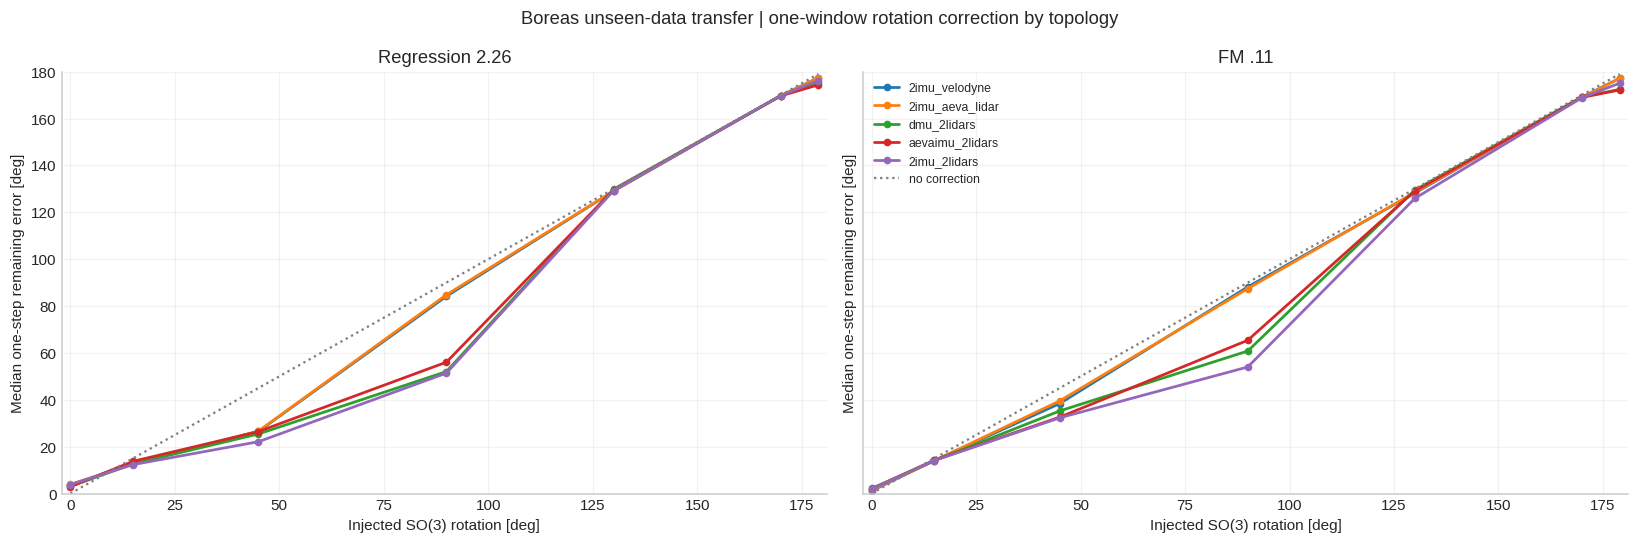

In [12]:
if not one_step_results.empty:
    summary = one_step_results.groupby(["topology","model","initial_angle_deg"],as_index=False).agg(
        median_final_deg=("final_error_deg","median"),improved_fraction=("improved","mean"))
    fig,axes = plt.subplots(1,2,figsize=(15,5),sharey=True)
    for ax,label in zip(axes,MODEL_LABELS):
        for topology in TOPOLOGIES:
            part = summary[(summary.topology==topology)&(summary.model==label)].sort_values("initial_angle_deg")
            ax.plot(part.initial_angle_deg,part.median_final_deg,"-o",linewidth=1.8,markersize=4,label=topology)
        ax.plot([0,179],[0,179],":",color="gray",label="no correction")
        ax.set(title=label, xlabel="Injected SO(3) rotation [deg]",ylabel="Median one-step remaining error [deg]",
               xlim=(-2,181),ylim=(0,180))
        ax.grid(alpha=.25)
    axes[1].legend(fontsize=8)
    fig.suptitle("Boreas unseen-data transfer | one-window rotation correction by topology")
    show_figure(fig,"03_one_step_angles_by_topology.png")

## 11. Select strictly consecutive physical windows for chronological rollouts

A rollout carries the model's updated calibration from one **new physical window** to the next. No reinitialization between steps, no repeated inference on one frozen window, and no post-hoc alignment. If the valid-window sequence has a gap, stop rather than crossing it.

In [13]:
rollout_end = len(boreas_windows) if ROLLOUT_NUM_WINDOWS is None else min(len(boreas_windows),ROLLOUT_START+ROLLOUT_NUM_WINDOWS)
if ROLLOUT_START >= len(boreas_windows):
    raise ValueError("ROLLOUT_START is outside the available physical windows")
rollout_indices = [ROLLOUT_START]
for i in range(ROLLOUT_START+1,rollout_end):
    if window_records[i][0] - window_records[rollout_indices[-1]][0] != STRIDE_NS:
        print(f"Stopping at physical gap before window {i}: not stitching nonconsecutive measurements")
        break
    rollout_indices.append(i)
if not rollout_indices:
    raise RuntimeError("No rollout windows")
rollout_starts_ns = [window_records[i][0] for i in rollout_indices]
rollout_full = [to_device(boreas_windows[i]) for i in rollout_indices]
rollout_by_topology = {topology:[make_topology_window(w,topology) for w in rollout_full]
                       for topology in TOPOLOGIES}
rollout_elapsed_s = np.r_[0.,[(start-rollout_starts_ns[0]+WINDOW_NS)*1e-9 for start in rollout_starts_ns]]
print(f"Consecutive rollout: {len(rollout_indices)} physical windows spanning "
      f"{rollout_elapsed_s[-1]:.1f} s, shared exactly across all topologies")

Consecutive rollout: 15 physical windows spanning 75.0 s, shared exactly across all topologies


## 12. Chronological *single-sensor* fault recovery

For each topology, separately corrupt every included sensor. Compare 0°, 15°, 45°, 90°, 130°, 170°, and 179° about selected axes, while all other physical sensors in that topology remain nominal. Both models receive exactly identical initial conditions and chronological measurements; **only the corrupted sensor is updated** so the result isolates that head's ability to generalize.

In [14]:
@torch.inference_mode()
def run_single_fault_rollout(topology, key, angle, axis):
    windows = rollout_by_topology[topology]
    reference = windows[0].current_calibration
    start = inject_fault(reference,key,np.eye(3)[axis]*angle)
    state_by_model = {label:clone_states(start) for label in MODELS}
    rows = []
    for step in range(len(windows)+1):
        for label,model in MODELS.items():
            current = state_by_model[label]
            deg,ms = errors_for(current,reference,key)
            rows.append(dict(topology=topology,sensor=key,model=label,axis="xyz"[axis],
                 initial_angle_deg=angle,step=step,elapsed_s=rollout_elapsed_s[step],
                 rotation_error_deg=deg,tau_error_ms=ms))
            if step < len(windows):
                prediction = calibration_forward(windows[step],current,model)
                state_by_model[label] = apply_updates(current,prediction,(key,),update_rotation=True,update_tau=False)
    return rows

single_fault_rows = []
if RUN_SINGLE_SENSOR_ROLLOUTS:
    cases = [(topology,key,angle,axis) for topology,keys in TOPOLOGIES.items() for key in keys
             for angle in ROTATION_ANGLES_DEG for axis in (ROLLOUT_AXES if angle else ROLLOUT_AXES[:1])]
    for topology,key,angle,axis in tqdm(cases,desc="Boreas sequential single-sensor faults"):
        single_fault_rows.extend(run_single_fault_rollout(topology,key,angle,axis))
    single_fault_rollouts = pd.DataFrame(single_fault_rows)
    if SAVE_RESULTS:
        single_fault_rollouts.to_csv(OUT/"single_sensor_chronological_rollouts.csv",index=False)
    print("Rows:",len(single_fault_rollouts),"| unique physical windows:",len(rollout_indices))
else:
    single_fault_rollouts = pd.DataFrame()
    print("Single-sensor rollouts disabled")

Boreas sequential single-sensor faults:   0%|          | 0/304 [00:00<?, ?it/s]

Rows: 9728 | unique physical windows: 15


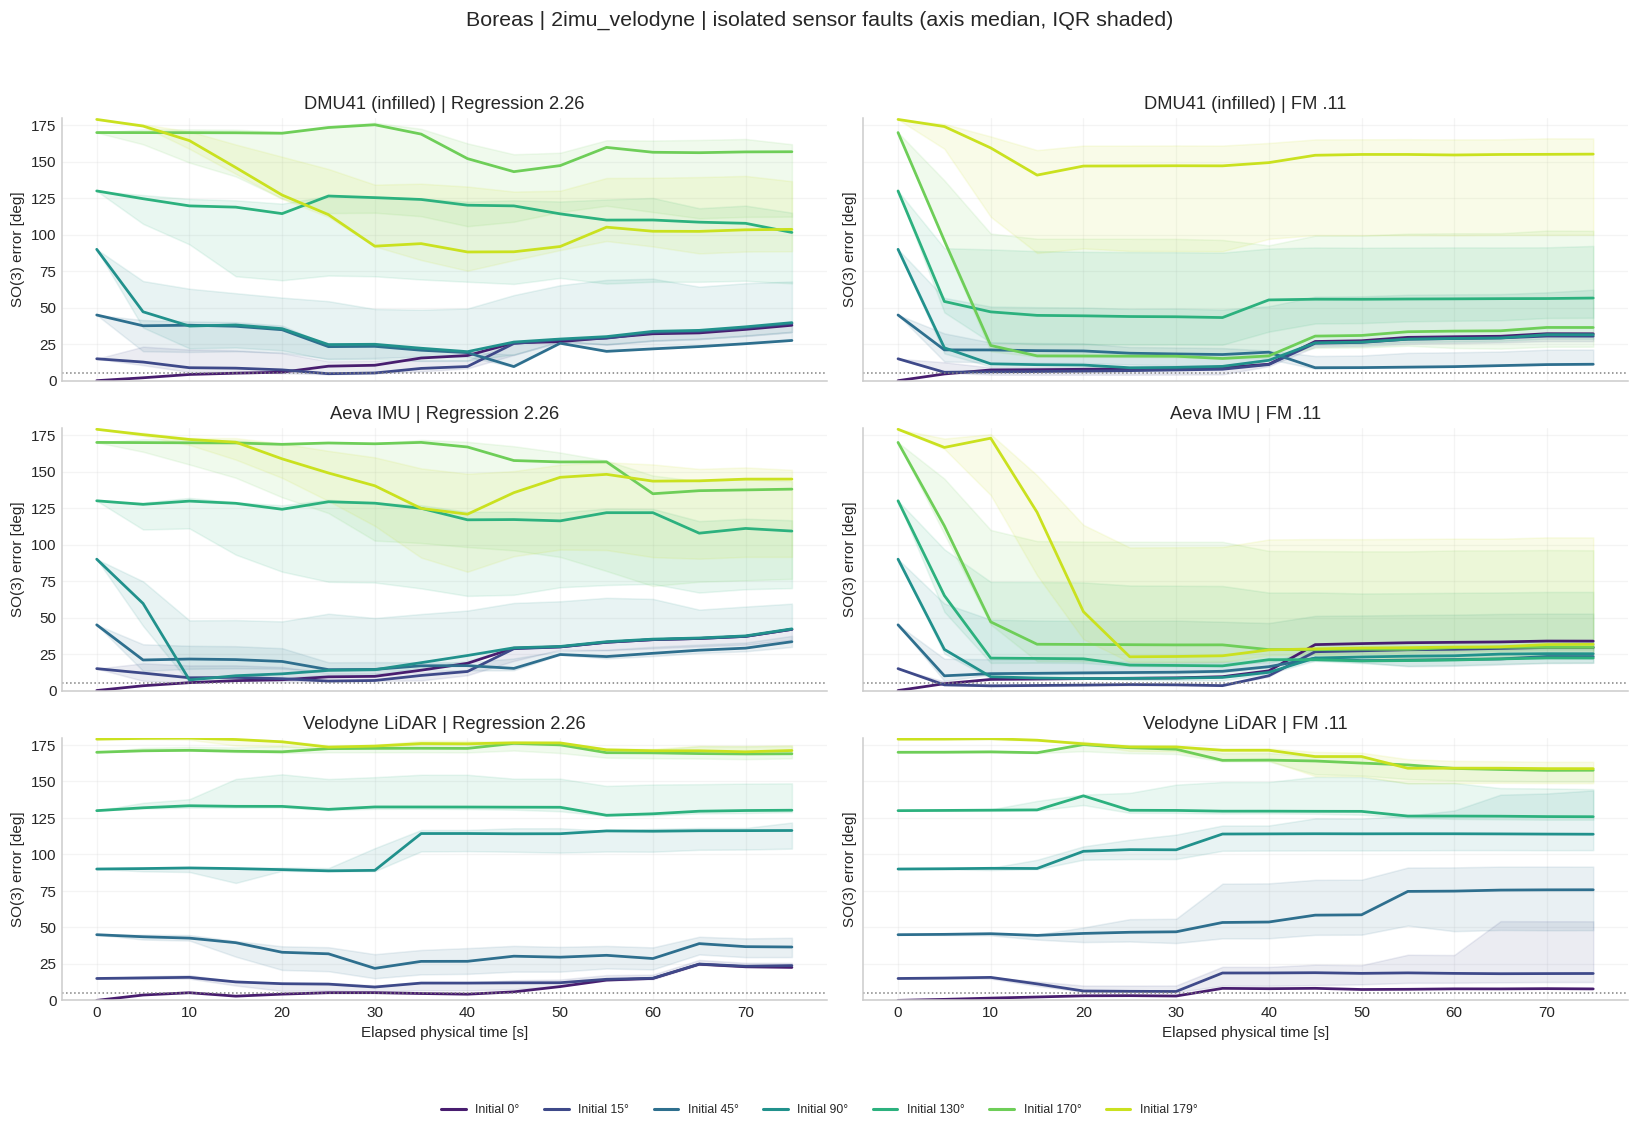

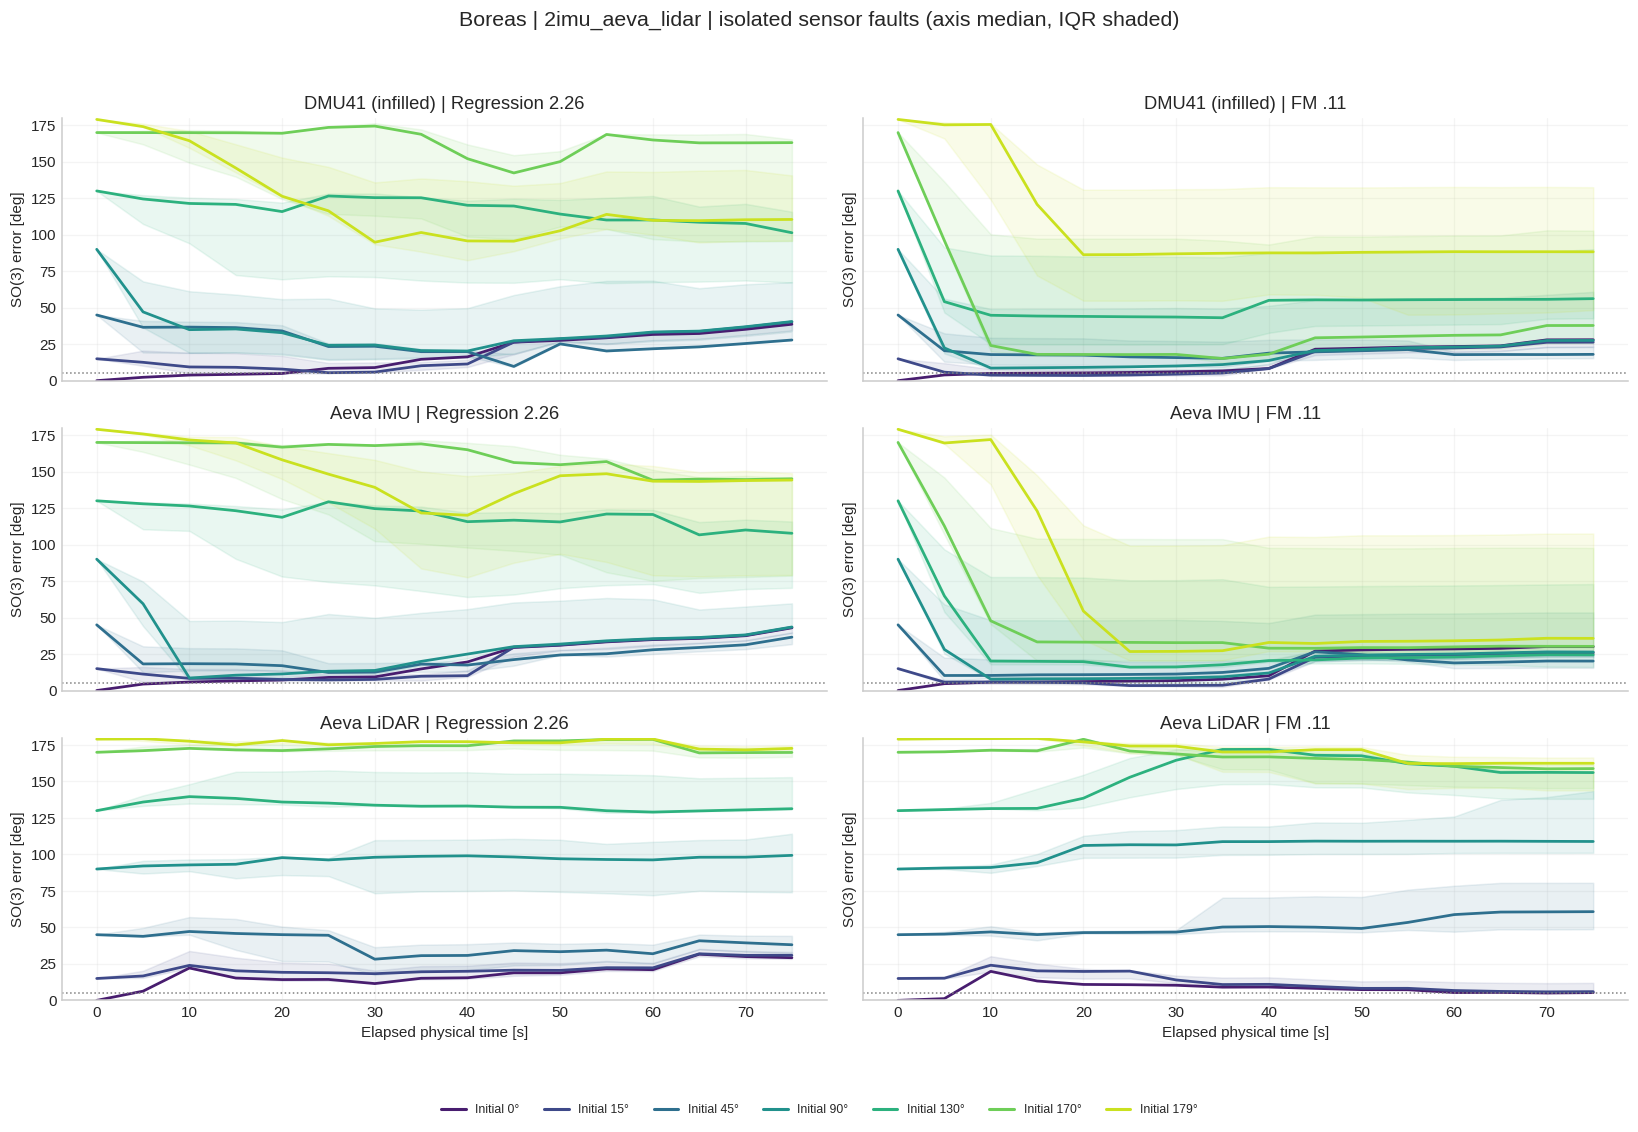

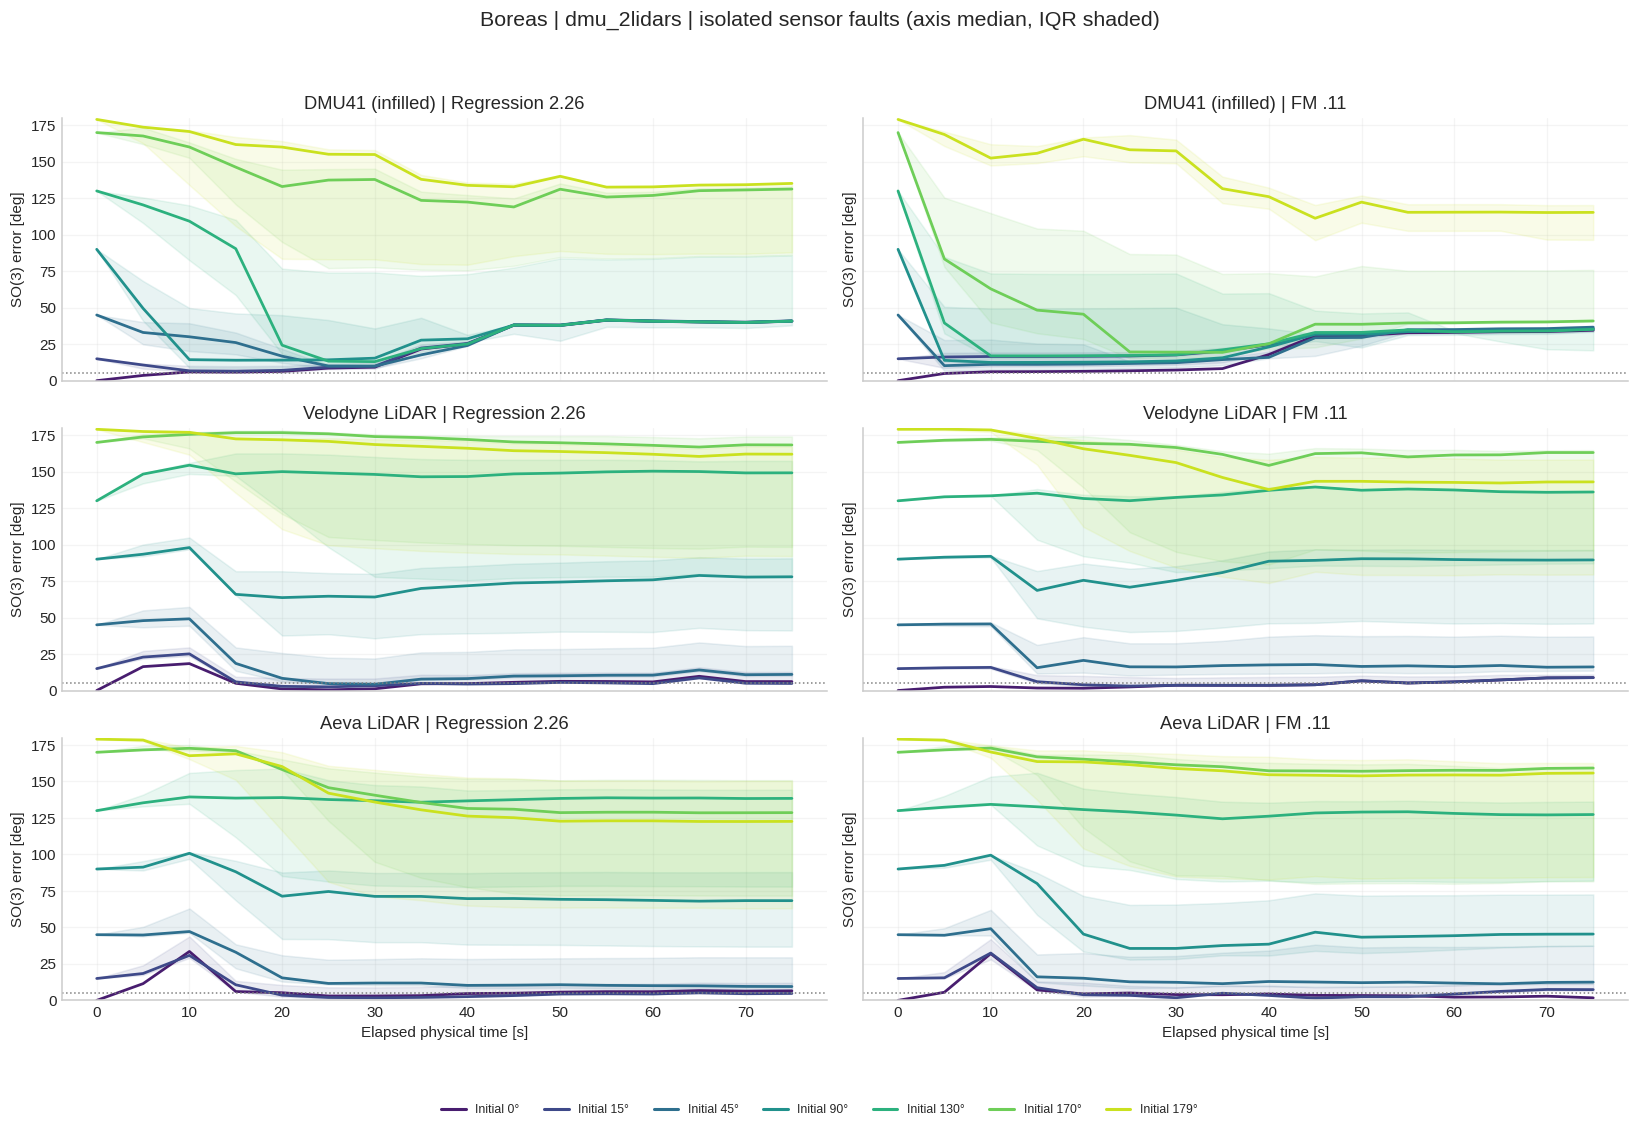

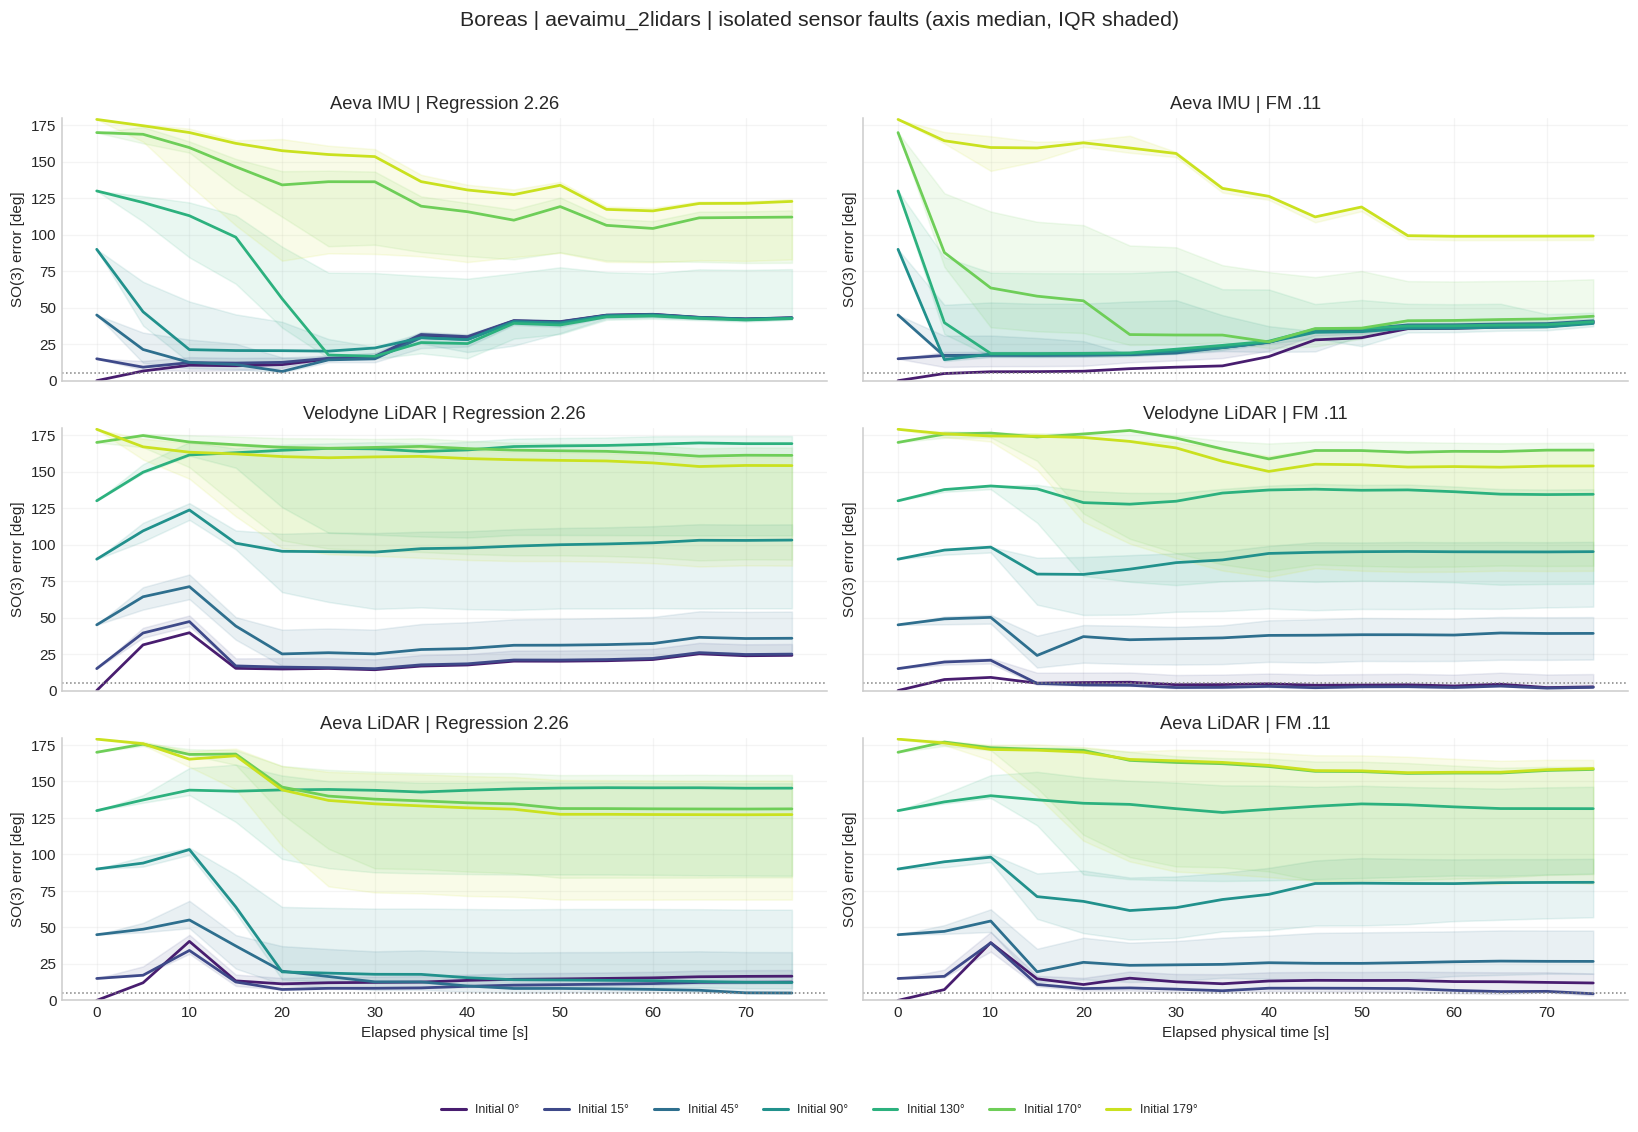

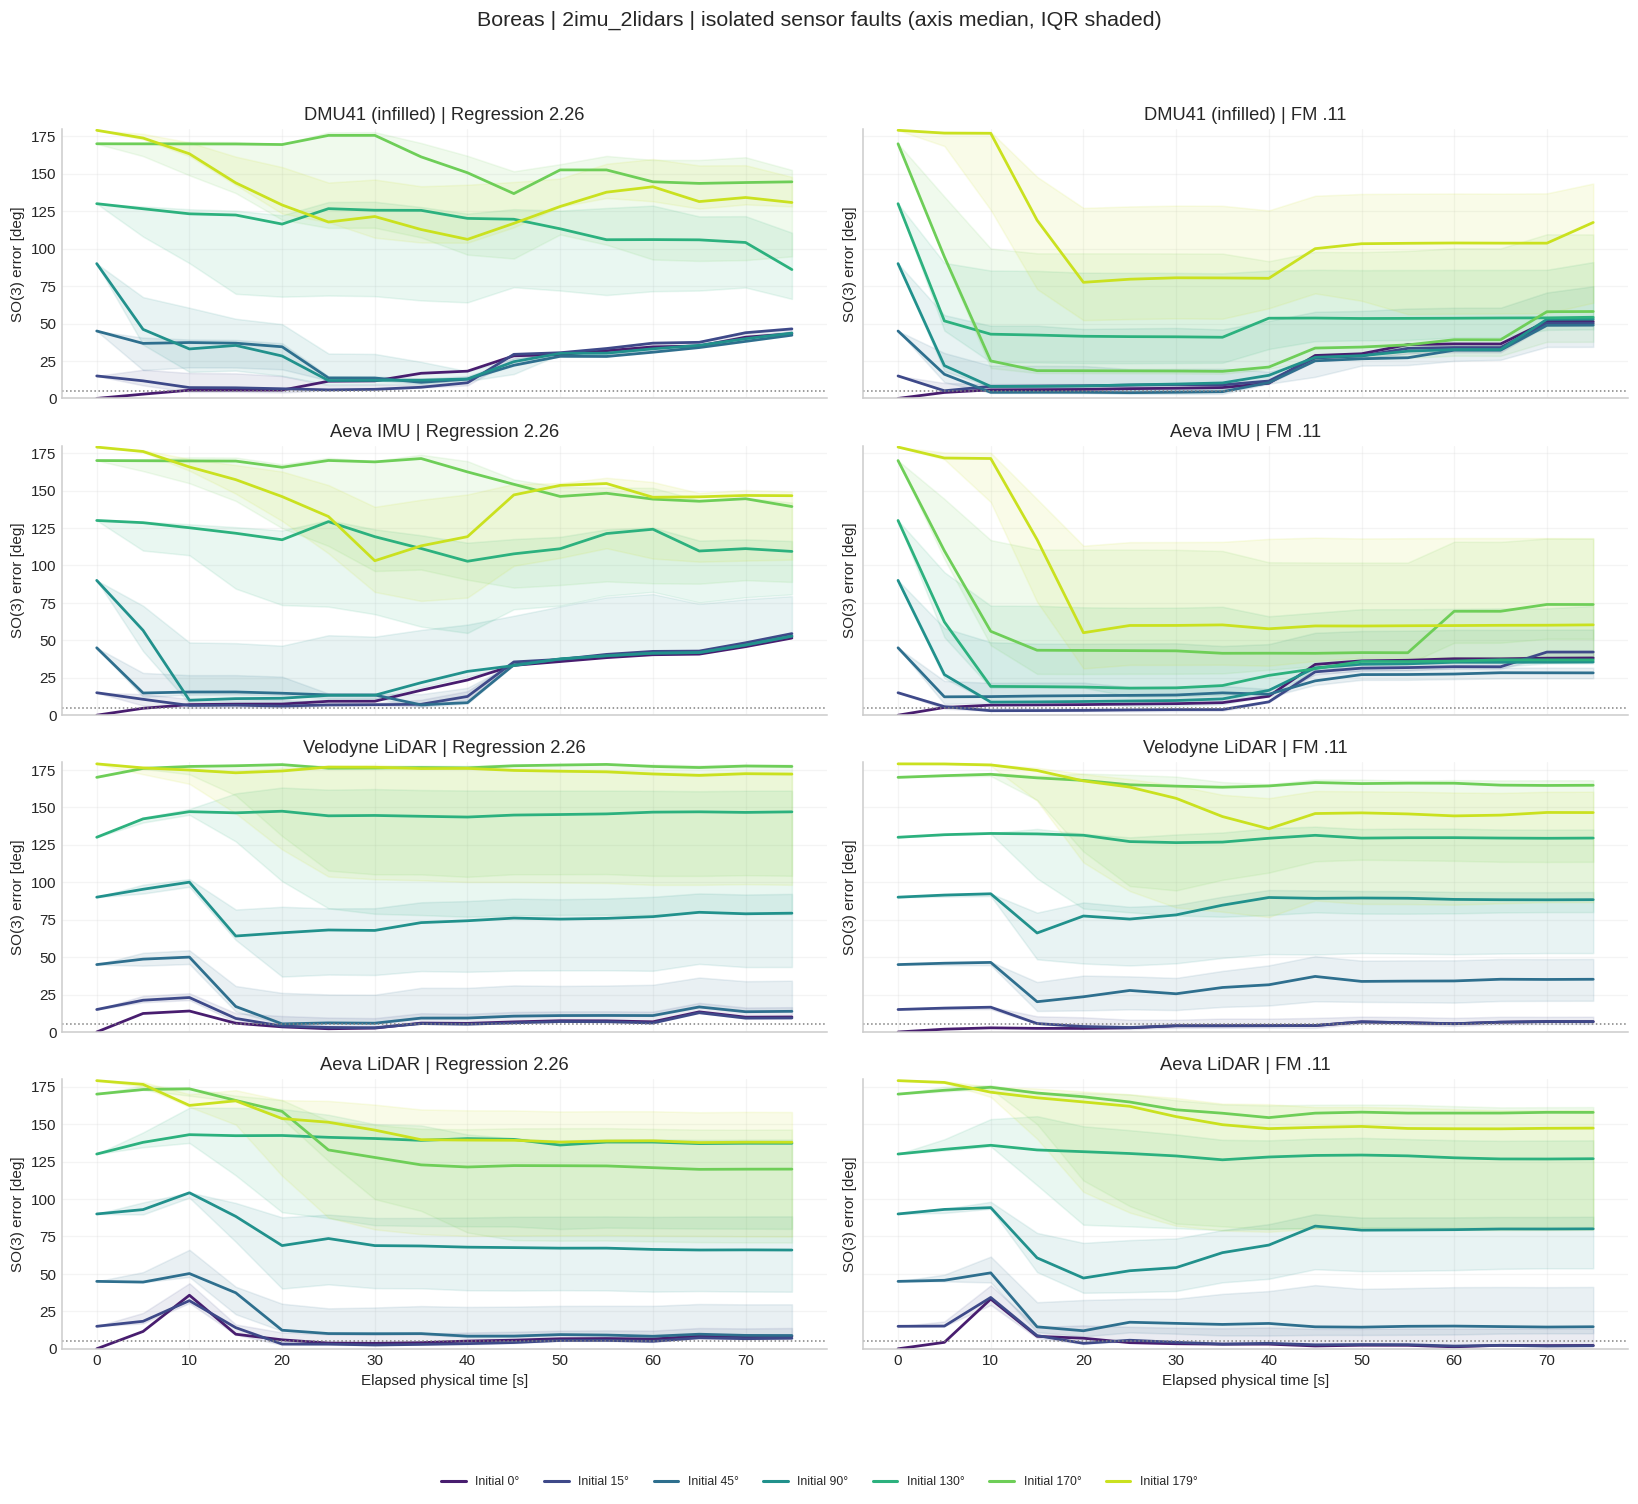

In [15]:
if not single_fault_rollouts.empty:
    for topology, keys in TOPOLOGIES.items():
        fig, axes = plt.subplots(len(keys),2,figsize=(15,3.3*len(keys)),sharex=True,sharey=True,squeeze=False)
        for row_index,key in enumerate(keys):
            for col_index,label in enumerate(MODEL_LABELS):
                ax = axes[row_index,col_index]
                part = single_fault_rollouts[(single_fault_rollouts.topology==topology)&
                                             (single_fault_rollouts.sensor==key)&
                                             (single_fault_rollouts.model==label)]
                for angle in ROTATION_ANGLES_DEG:
                    group = part[part.initial_angle_deg==angle].groupby("step",as_index=False).agg(
                        elapsed_s=("elapsed_s","first"),median_deg=("rotation_error_deg","median"),
                        p25=("rotation_error_deg",lambda v:np.quantile(v,.25)),
                        p75=("rotation_error_deg",lambda v:np.quantile(v,.75)))
                    if group.empty:
                        continue
                    color = ANGLE_COLORS[angle]
                    ax.plot(group.elapsed_s,group.median_deg,color=color,linewidth=1.8,label=f"{angle:g}°")
                    if len(ROLLOUT_AXES)>1 and angle:
                        ax.fill_between(group.elapsed_s.to_numpy(float),group.p25.to_numpy(float),
                                        group.p75.to_numpy(float),color=color,alpha=.10)
                ax.axhline(ROTATION_CONVERGENCE_DEG,color="gray",ls=":",lw=1)
                ax.set(title=f"{SENSOR_LABELS[key]} | {label}",ylabel="SO(3) error [deg]",ylim=(0,180))
                ax.grid(alpha=.2)
                if row_index==len(keys)-1:
                    ax.set_xlabel("Elapsed physical time [s]")
        handles = [Line2D([],[],color=ANGLE_COLORS[a],lw=2,label=f"Initial {a:g}°") for a in ROTATION_ANGLES_DEG]
        fig.legend(handles=handles,loc="lower center",ncol=len(handles),bbox_to_anchor=(.5,-.015),fontsize=8)
        fig.suptitle(f"Boreas | {topology} | isolated sensor faults (axis median, IQR shaded)",fontsize=14,y=1.01)
        fig.tight_layout(rect=(0,.05,1,.98))
        if SAVE_RESULTS:
            fig.savefig(OUT/f"04_single_sensor_error_vs_time_{topology}.png",dpi=PLOT_DPI,bbox_inches="tight")
        if SHOW_PLOTS:
            plt.show()
        plt.close(fig)

## 13. Sustained convergence and cross-topology comparison

We score each *individual axis/fault case* before aggregation. Sustained convergence means every one of the final `STABLE_LAST_N_WINDOWS` post-update errors is below 5°. A topology with four sensors has more fault cases than a three-sensor topology; pooled scores are useful, but **matched physical-sensor comparisons** below are more defensible.

,topology,model,initial_angle_deg,median_final_deg,p25,p75,stable_fraction,worsened_fraction,cases
0,2imu_2lidars,FM .11,0.0,22.551,5.723,41.506,0.250,1.000,4
1,2imu_2lidars,FM .11,15.0,30.148,6.171,44.190,0.250,0.583,12
2,2imu_2lidars,FM .11,45.0,31.688,18.598,49.774,0.000,0.333,12
3,2imu_2lidars,FM .11,90.0,65.897,35.057,90.297,0.000,0.250,12
4,2imu_2lidars,FM .11,130.0,81.582,36.565,128.208,0.000,0.167,12
...,...,...,...,...,...,...,...,...,...
65,dmu_2lidars,Regression 2.26,45.0,40.837,9.484,41.253,0.000,0.222,9
66,dmu_2lidars,Regression 2.26,90.0,41.018,34.954,77.932,0.000,0.222,9
67,dmu_2lidars,Regression 2.26,130.0,130.836,40.689,149.161,0.000,0.556,9
68,dmu_2lidars,Regression 2.26,170.0,131.292,41.012,168.260,0.000,0.222,9


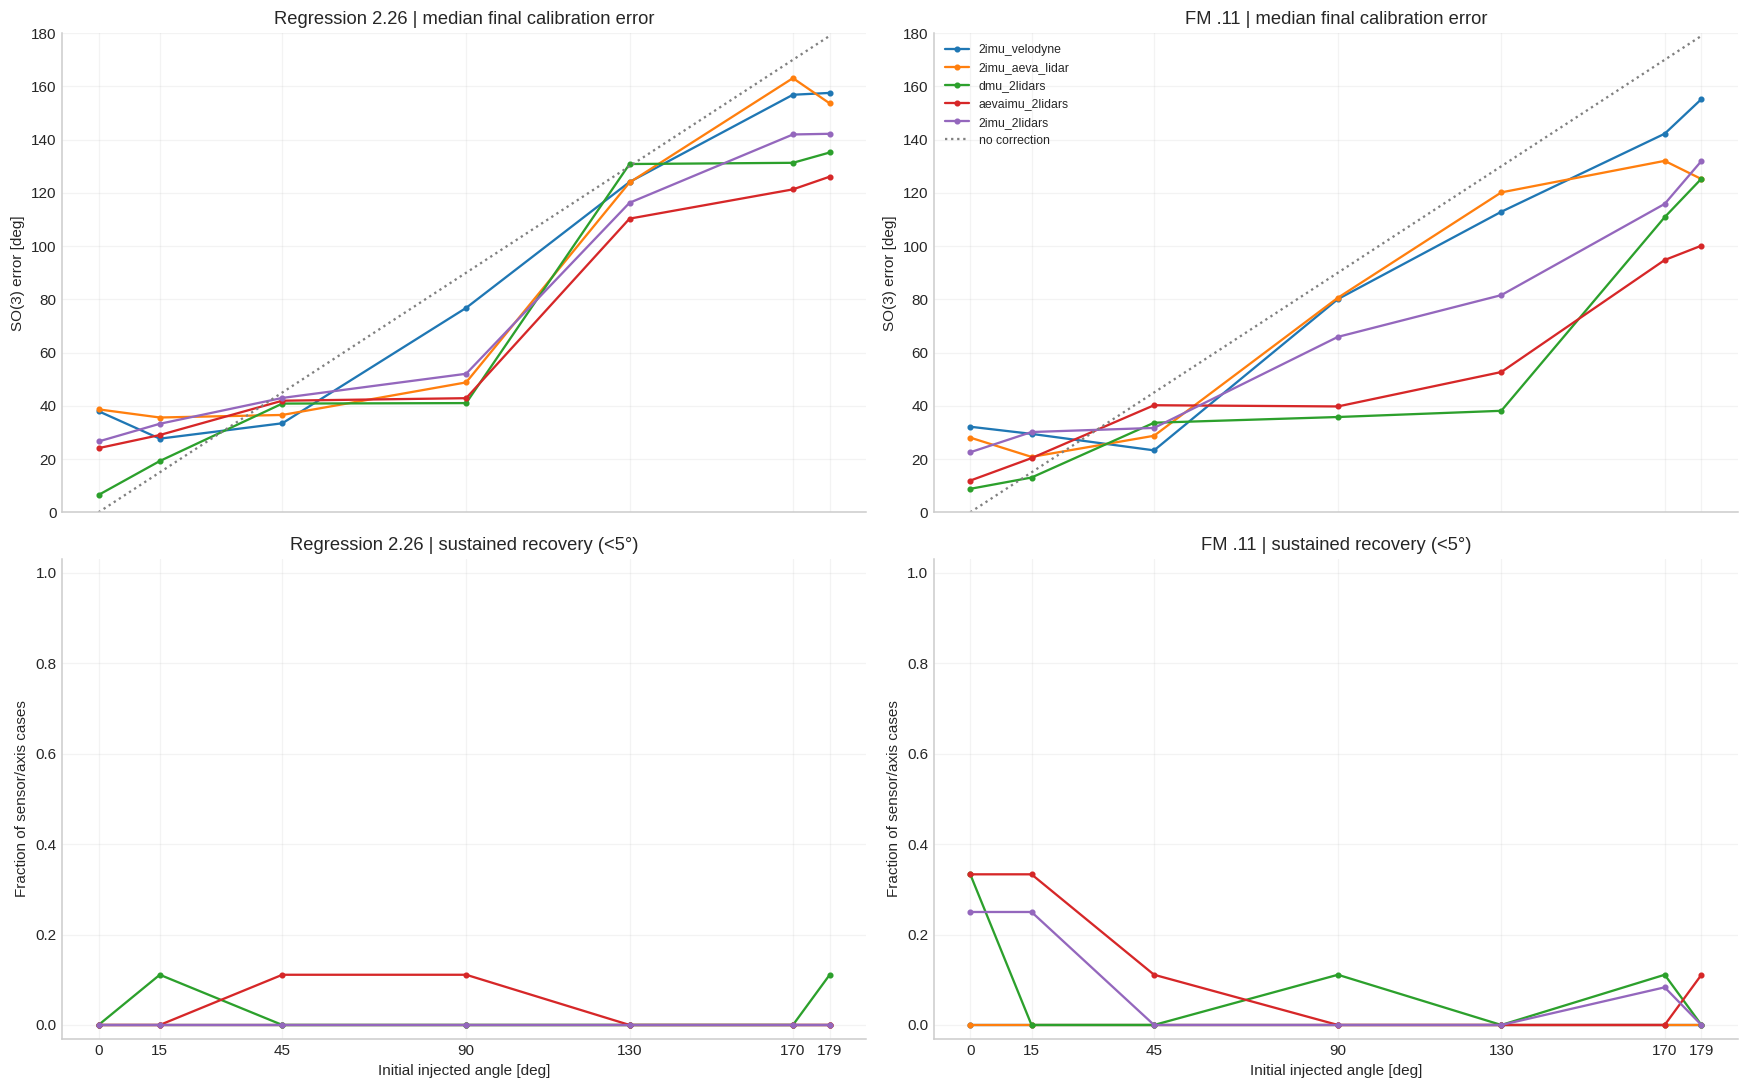

In [16]:
single_summary = pd.DataFrame()
if not single_fault_rollouts.empty:
    summary_rows = []
    for (topology,key,label,axis,angle),group in single_fault_rollouts.groupby(
        ["topology","sensor","model","axis","initial_angle_deg"],sort=False):
        group = group.sort_values("step")
        tail = group.iloc[-min(STABLE_LAST_N_WINDOWS,len(group)-1):]
        summary_rows.append(dict(topology=topology,sensor=key,model=label,axis=axis,
            initial_angle_deg=float(angle),initial_deg=float(group.rotation_error_deg.iloc[0]),
            final_deg=float(group.rotation_error_deg.iloc[-1]),
            best_post_update_deg=float(group.rotation_error_deg.iloc[1:].min()),
            stable_convergence=bool((tail.rotation_error_deg<ROTATION_CONVERGENCE_DEG).all()),
            degraded_from_initial=bool(group.rotation_error_deg.iloc[-1]>group.rotation_error_deg.iloc[0]+1e-5)))
    single_summary = pd.DataFrame(summary_rows)
    pooled = single_summary.groupby(["topology","model","initial_angle_deg"],as_index=False).agg(
        median_final_deg=("final_deg","median"), p25=("final_deg",lambda s:s.quantile(.25)),
        p75=("final_deg",lambda s:s.quantile(.75)),stable_fraction=("stable_convergence","mean"),
        worsened_fraction=("degraded_from_initial","mean"),cases=("final_deg","size"))
    display(pooled.round(3))
    if SAVE_RESULTS:
        single_summary.to_csv(OUT/"single_sensor_rollout_case_summary.csv",index=False)
        pooled.to_csv(OUT/"single_sensor_pooled_summary.csv",index=False)
    fig,axs = plt.subplots(2,2,figsize=(16,10),sharex=True)
    for j,label in enumerate(MODEL_LABELS):
        for topo in TOPOLOGIES:
            sub = pooled[(pooled.topology==topo)&(pooled.model==label)].sort_values("initial_angle_deg")
            axs[0,j].plot(sub.initial_angle_deg,sub.median_final_deg,"-o",markersize=3,label=topo)
            axs[1,j].plot(sub.initial_angle_deg,sub.stable_fraction,"-o",markersize=3,label=topo)
        axs[0,j].plot([0,179],[0,179],":",color="gray",label="no correction")
        axs[0,j].set(title=f"{label} | median final calibration error",ylabel="SO(3) error [deg]",ylim=(0,180))
        axs[1,j].set(title=f"{label} | sustained recovery (<{ROTATION_CONVERGENCE_DEG:g}°)",
                       xlabel="Initial injected angle [deg]",ylabel="Fraction of sensor/axis cases",ylim=(-.03,1.03))
        for ax in axs[:,j]:
            ax.set_xticks(ROTATION_ANGLES_DEG)
            ax.grid(alpha=.23)
    axs[0,1].legend(fontsize=8)
    show_figure(fig,"05_single_sensor_cross_topology_final_and_success.png")

In [17]:
if not single_summary.empty:
    # Paired comparison: same physical sensor, same axis and angle, and same chronological windows.
    for label in MODEL_LABELS:
        frame = single_summary[single_summary.model==label]
        table = frame.pivot_table(index=["sensor","initial_angle_deg","axis"],columns="topology",values="final_deg")
        print("Matched per-sensor final SO(3) errors:",label)
        display(table.groupby(level=["sensor","initial_angle_deg"]).median().round(2))
    # A 4-sensor network is not automatically more accurate. Show paired delta vs an appropriate 3-sensor baseline.
    pairs = (("2imu_velodyne","2imu_2lidars"),("2imu_aeva_lidar","2imu_2lidars"),
             ("dmu_2lidars","2imu_2lidars"),("aevaimu_2lidars","2imu_2lidars"))
    paired_rows=[]
    for baseline,full in pairs:
        A=single_summary[single_summary.topology==baseline]
        B=single_summary[single_summary.topology==full]
        joined=A.merge(B,on=["sensor","model","axis","initial_angle_deg"],suffixes=("_baseline","_full"))
        for _,r in joined.iterrows():
            paired_rows.append(dict(baseline=baseline,sensor=r.sensor,model=r.model,
                initial_angle_deg=r.initial_angle_deg,full_minus_baseline_deg=r.final_deg_full-r.final_deg_baseline))
    paired_topology_deltas=pd.DataFrame(paired_rows)
    display(paired_topology_deltas.groupby(["baseline","model","initial_angle_deg"],as_index=False)
            .agg(median_full_minus_baseline_deg=("full_minus_baseline_deg","median"),
                 n=("full_minus_baseline_deg","size")).round(3))
    if SAVE_RESULTS:
        paired_topology_deltas.to_csv(OUT/"matched_four_vs_three_sensor_deltas.csv",index=False)

Matched per-sensor final SO(3) errors: Regression 2.26


topology                          2imu_2lidars  2imu_aeva_lidar  \
sensor         initial_angle_deg                                  
imu_aeva       0.0                       51.50            42.97   
               15.0                      54.48            43.28   
               45.0                      52.72            36.56   
               90.0                      52.79            43.53   
               130.0                    109.34           107.74   
               170.0                    139.30           145.09   
               179.0                    146.54           144.21   
imu_dmu        0.0                       43.16            38.66   
               15.0                      46.40            40.22   
               45.0                      42.21            27.86   
               90.0                      43.61            40.51   
               130.0                     86.01           101.36   
               170.0                    144.59           163.11   
               179.0                    130.80           110.47   
lidar_aeva     0.0                        8.40            29.23   
               15.0                       7.04            30.88   
               45.0                       8.85            38.11   
               90.0                      65.92            99.37   
               130.0                    137.19           131.32   
               170.0                    119.94           169.88   
               179.0                    137.85           172.67   
lidar_velodyne 0.0                       10.03              NaN   
               15.0                       9.33              NaN   
               45.0                      13.80              NaN   
               90.0                      79.33              NaN   
               130.0                    146.97              NaN   
               170.0                    177.27              NaN   
               179.0                    172.15              NaN   

topology                          2imu_velodyne  aevaimu_2lidars  dmu_2lidars  
sensor         initial_angle_deg                                               
imu_aeva       0.0                        41.90            43.05          NaN  
               15.0                       41.93            43.12          NaN  
               45.0                       33.44            42.88          NaN  
               90.0                       42.25            42.86          NaN  
               130.0                     109.25            42.54          NaN  
               170.0                     137.99           112.08          NaN  
               179.0                     144.87           122.83          NaN  
imu_dmu        0.0                        37.97              NaN        40.74  
               15.0                       39.15              NaN        40.98  
               45.0                       27.55              NaN        40.86  
               90.0                       39.76              NaN        40.80  
               130.0                     101.56              NaN        40.81  
               170.0                     156.86              NaN       131.29  
               179.0                     103.69              NaN       135.17  
lidar_aeva     0.0                          NaN            16.57         6.51  
               15.0                         NaN            12.59         4.75  
               45.0                         NaN             5.07         9.48  
               90.0                         NaN            12.23        68.32  
               130.0                        NaN           145.41       138.40  
               170.0                        NaN           131.22       128.64  
               179.0                        NaN           127.30       122.63  
lidar_velodyne 0.0                        22.58            24.09         6.12  
               15.0                       23.86            24.94     

Matched per-sensor final SO(3) errors: FM .11


topology                          2imu_2lidars  2imu_aeva_lidar  \
sensor         initial_angle_deg                                  
imu_aeva       0.0                       38.21            30.06   
               15.0                      42.18            25.84   
               45.0                      28.26            20.17   
               90.0                      35.50            26.40   
               130.0                     36.90            24.44   
               170.0                     73.89            30.26   
               179.0                     60.32            35.74   
imu_dmu        0.0                       51.39            28.04   
               15.0                      50.26            26.37   
               45.0                      48.93            18.02   
               90.0                      52.93            27.58   
               130.0                     54.18            56.19   
               170.0                     58.01            37.81   
               179.0                    117.47            88.29   
lidar_aeva     0.0                        2.22             5.31   
               15.0                       2.01             5.98   
               45.0                      14.70            60.78   
               90.0                      80.06           108.87   
               130.0                    126.88           156.08   
               170.0                    157.82           158.82   
               179.0                    147.32           162.46   
lidar_velodyne 0.0                        6.89              NaN   
               15.0                       6.94              NaN   
               45.0                      35.19              NaN   
               90.0                      88.34              NaN   
               130.0                    129.46              NaN   
               170.0                    164.72              NaN   
               179.0                    146.48              NaN   

topology                          2imu_velodyne  aevaimu_2lidars  dmu_2lidars  
sensor         initial_angle_deg                                               
imu_aeva       0.0                        33.85            39.70          NaN  
               15.0                       29.45            40.38          NaN  
               45.0                       23.26            41.02          NaN  
               90.0                       25.19            39.17          NaN  
               130.0                      22.22            40.39          NaN  
               170.0                      29.56            44.15          NaN  
               179.0                      31.62            99.12          NaN  
imu_dmu        0.0                        32.14              NaN        34.54  
               15.0                       30.49              NaN        35.78  
               45.0                       11.26              NaN        36.65  
               90.0                       31.50              NaN        35.41  
               130.0                      56.62              NaN        35.15  
               170.0                      36.43              NaN        40.91  
               179.0                     155.23              NaN       115.31  
lidar_aeva     0.0                          NaN            11.91         1.73  
               15.0                         NaN             4.56         7.37  
               45.0                         NaN            26.70        12.48  
               90.0                         NaN            80.89        45.42  
               130.0                        NaN           131.36       127.33  
               170.0                        NaN           158.23       159.21  
               179.0                        NaN           158.84       155.74  
lidar_velodyne 0.0                         7.86             2.51         8.81  
               15.0                       18.41             2.20     

,baseline,model,initial_angle_deg,median_full_minus_baseline_deg,n
0,2imu_aeva_lidar,FM .11,0.0,8.154,3
1,2imu_aeva_lidar,FM .11,15.0,14.773,9
2,2imu_aeva_lidar,FM .11,45.0,7.060,9
3,2imu_aeva_lidar,FM .11,90.0,2.827,9
4,2imu_aeva_lidar,FM .11,130.0,3.866,9
5,2imu_aeva_lidar,FM .11,170.0,0.843,9
6,2imu_aeva_lidar,FM .11,179.0,0.947,9
7,2imu_aeva_lidar,Regression 2.26,0.0,4.499,3
8,2imu_aeva_lidar,Regression 2.26,15.0,7.672,9
9,2imu_aeva_lidar,Regression 2.26,45.0,9.558,9


## 14. Whole-rig rollouts: corrupt **all participating sensors** simultaneously

Each physical sensor gets a different fixed rotation axis, with equal initial geodesic magnitude. This is intentionally harder than one-sensor errors and exposes dependence on relative rig geometry. **Both absolute and pairwise rotation errors** are measured: pairwise errors are invariant to a *common* rotation of every sensor and help diagnose the gauge ambiguity. All sensor corrections at step *k* use predictions from the same pre-update state.

In [18]:
@torch.inference_mode()
def run_all_sensor_rollout(topology,angle):
    windows = rollout_by_topology[topology]
    ref = windows[0].current_calibration
    initial = clone_states(ref)
    for key in TOPOLOGIES[topology]:
        direction = np.asarray(ALL_SENSOR_DIRECTIONS[key],dtype=float)
        direction /= np.linalg.norm(direction)
        initial[key] = inject_fault(ref,key,direction*angle)[key]
    states_by_model = {label:clone_states(initial) for label in MODELS}
    rows=[]
    for step in range(len(windows)+1):
        for label,model in MODELS.items():
            states = states_by_model[label]
            sensor_err = {key:errors_for(states,ref,key)[0] for key in TOPOLOGIES[topology]}
            rows.append(dict(topology=topology,model=label,initial_angle_deg=angle,step=step,
                elapsed_s=rollout_elapsed_s[step],max_absolute_deg=max(sensor_err.values()),
                mean_absolute_deg=float(np.mean(list(sensor_err.values()))),
                max_pairwise_deg=worst_pairwise_rotation_error(states,ref),
                **{f"err_{key}_deg":value for key,value in sensor_err.items()}))
            if step < len(windows):
                prediction = calibration_forward(windows[step],states,model)
                states_by_model[label] = apply_updates(states,prediction,TOPOLOGIES[topology],
                                                       update_rotation=True,update_tau=False)
    return rows

all_sensor_rows=[]
if RUN_ALL_SENSOR_ROLLOUTS:
    cases=[(topology,angle) for topology in TOPOLOGIES for angle in ALL_SENSOR_ANGLES_DEG]
    for topology,angle in tqdm(cases,desc="Whole-rig Boreas rollouts"):
        all_sensor_rows.extend(run_all_sensor_rollout(topology,angle))
    all_sensor_rollouts=pd.DataFrame(all_sensor_rows)
    display(all_sensor_rollouts[all_sensor_rollouts.step==len(rollout_indices)]
            [["topology","model","initial_angle_deg","max_absolute_deg","mean_absolute_deg","max_pairwise_deg"]].round(3))
    if SAVE_RESULTS:
        all_sensor_rollouts.to_csv(OUT/"all_sensor_chronological_rollouts.csv",index=False)
else:
    all_sensor_rollouts=pd.DataFrame()
    print("Whole-rig experiments disabled")

Whole-rig Boreas rollouts:   0%|          | 0/30 [00:00<?, ?it/s]

,topology,model,initial_angle_deg,max_absolute_deg,mean_absolute_deg,max_pairwise_deg
30,2imu_velodyne,Regression 2.26,0.0,36.137,29.500,17.021
31,2imu_velodyne,FM .11,0.0,24.425,20.123,15.804
62,2imu_velodyne,Regression 2.26,45.0,26.613,20.296,37.762
63,2imu_velodyne,FM .11,45.0,31.619,15.290,39.686
94,2imu_velodyne,Regression 2.26,90.0,83.382,68.952,154.169
95,2imu_velodyne,FM .11,90.0,55.523,31.968,82.950
126,2imu_velodyne,Regression 2.26,130.0,133.220,96.451,162.472
127,2imu_velodyne,FM .11,130.0,149.183,98.512,145.881
158,2imu_velodyne,Regression 2.26,170.0,112.101,109.617,164.376
159,2imu_velodyne,FM .11,170.0,108.171,91.957,176.972


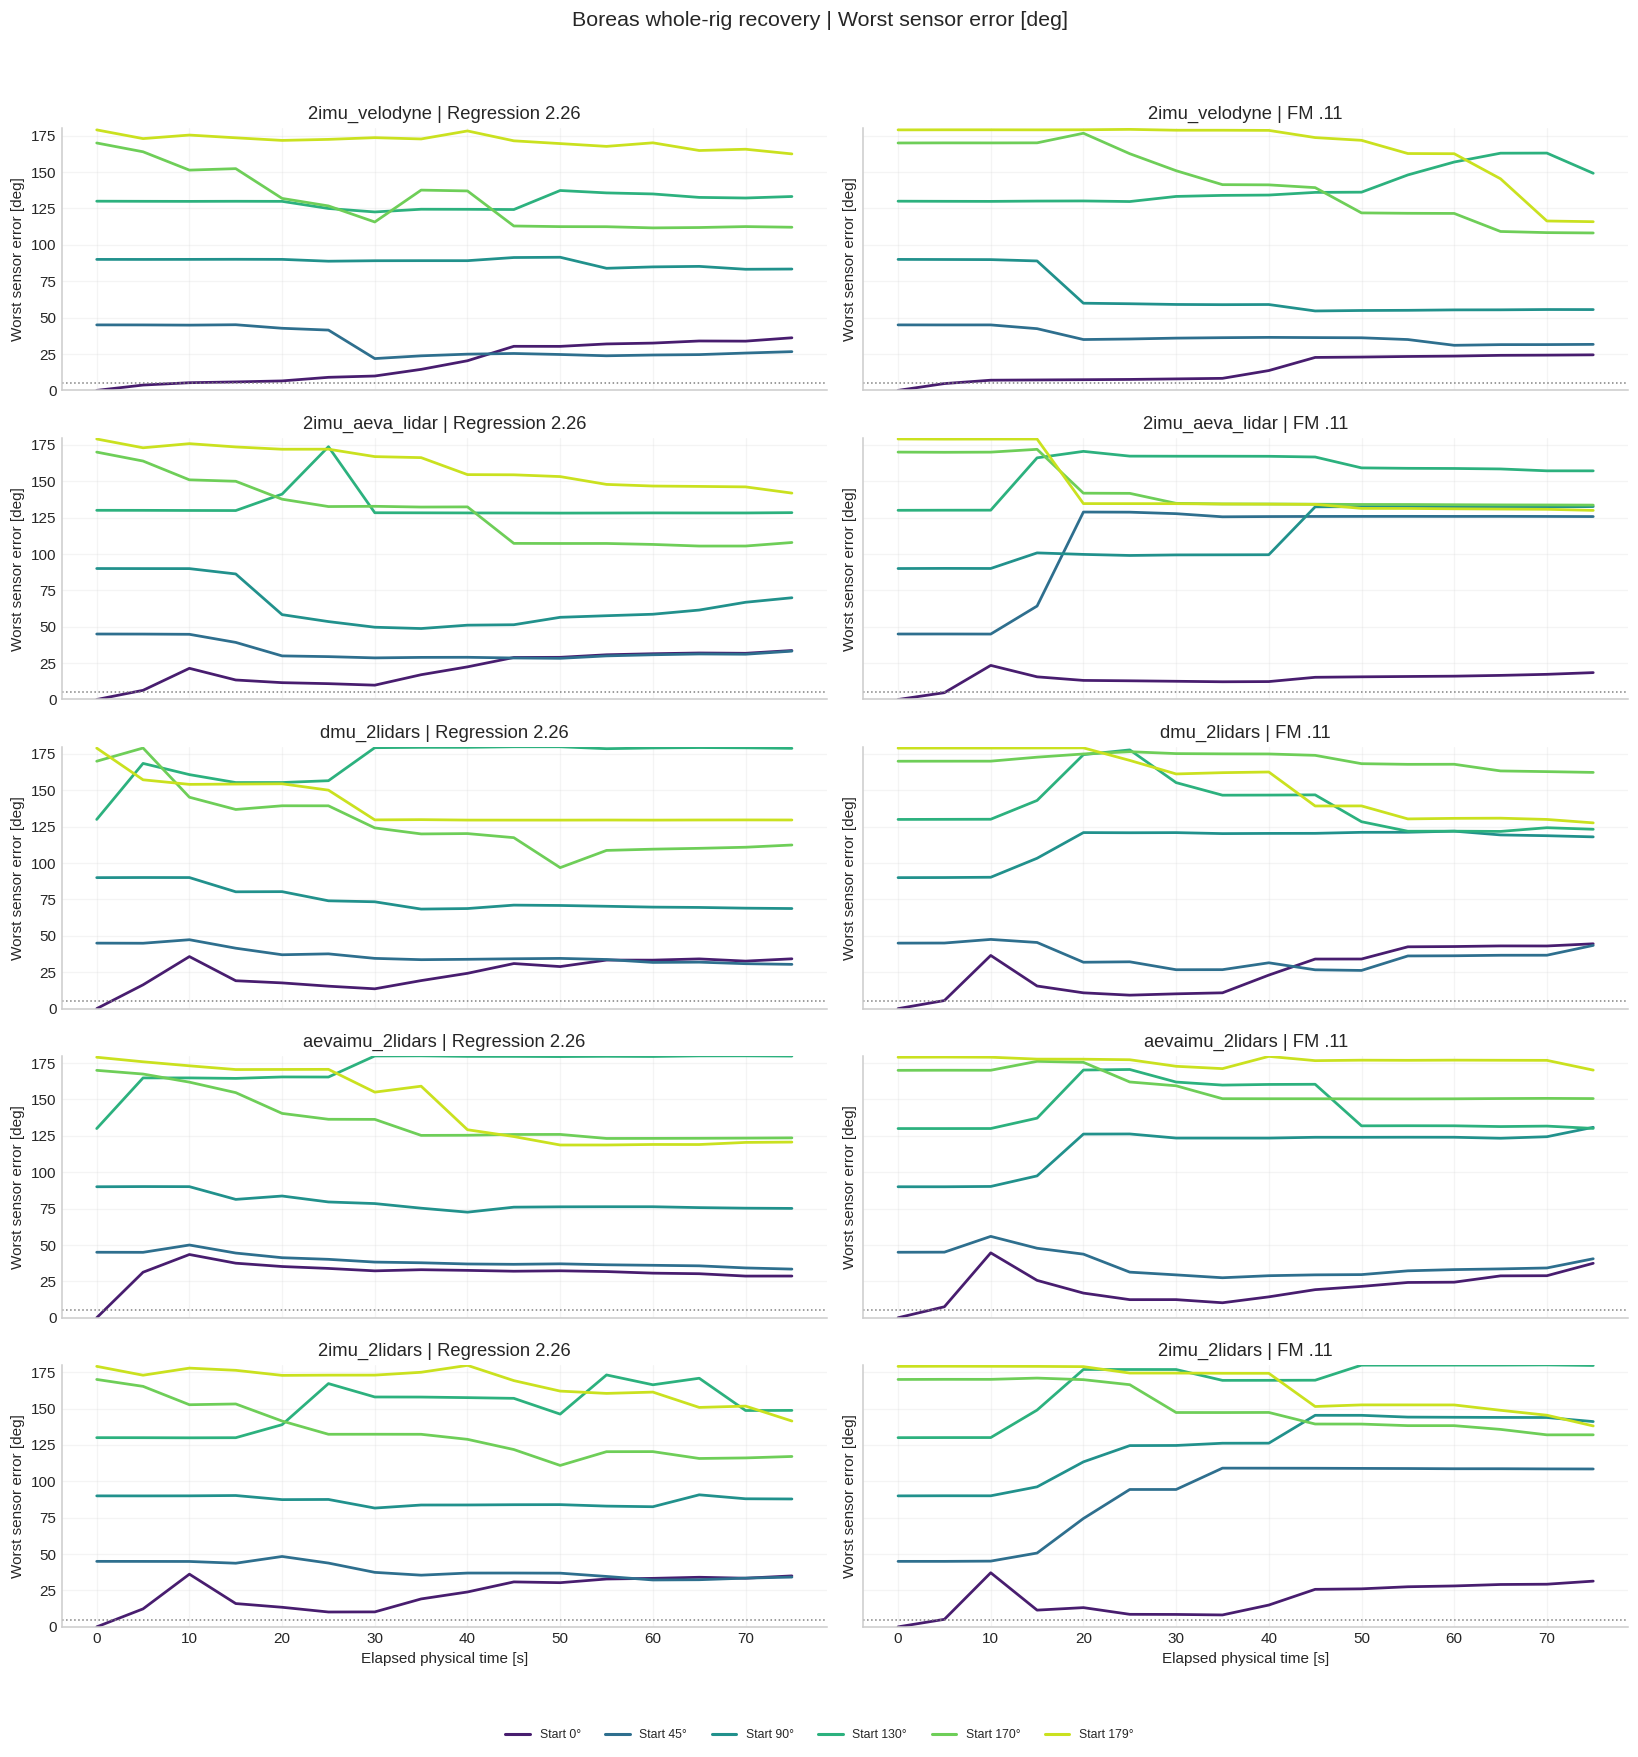

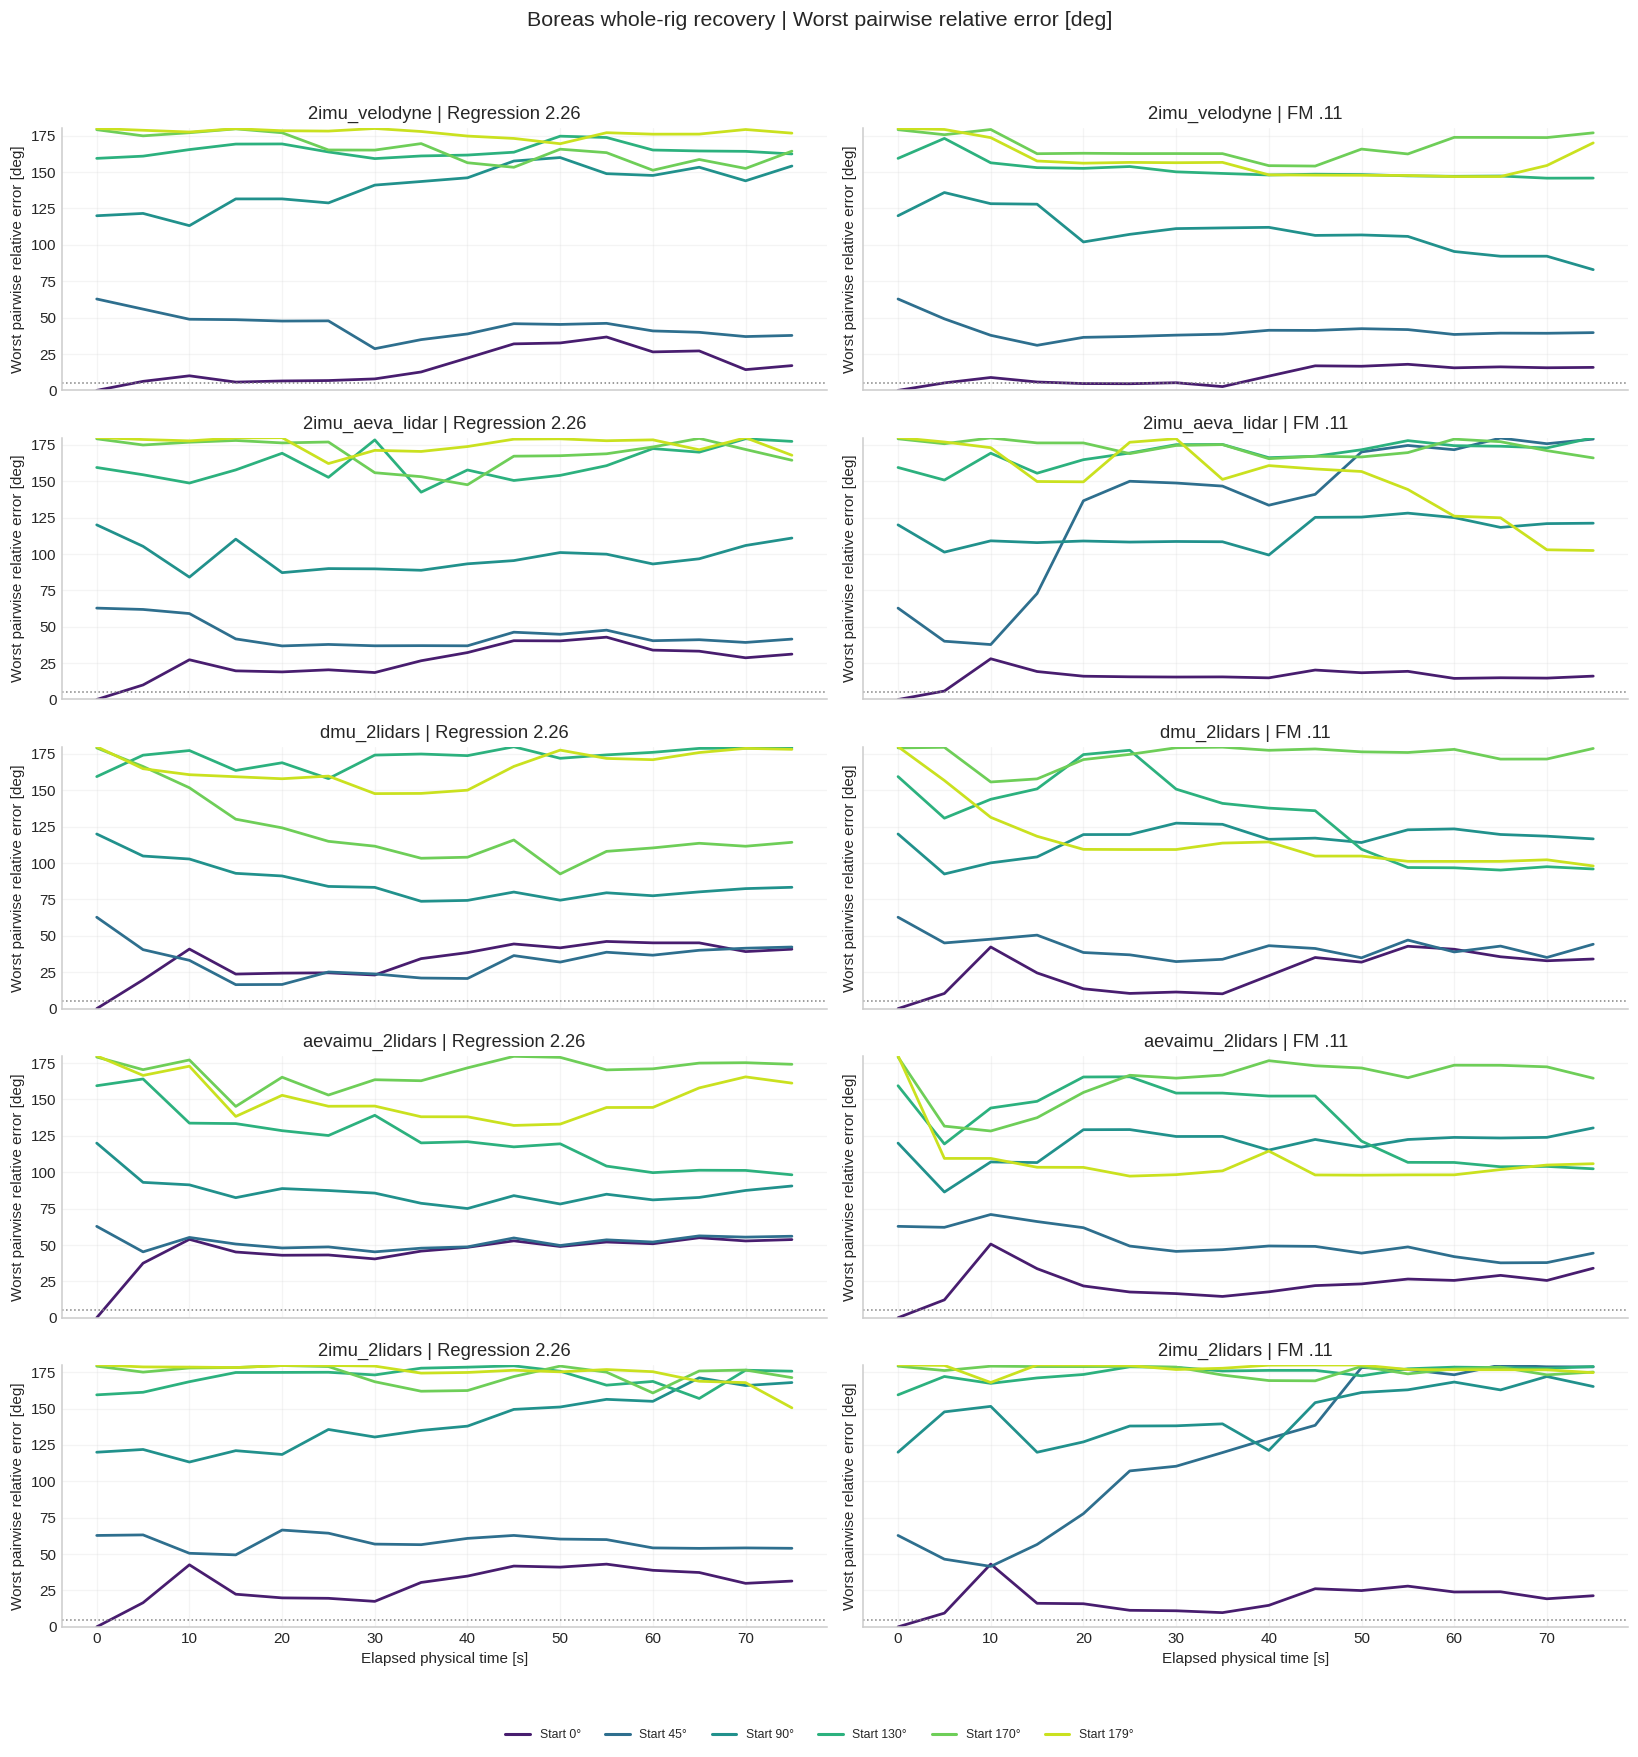

In [19]:
if not all_sensor_rollouts.empty:
    for metric,description,filename in (("max_absolute_deg","Worst sensor error [deg]","06_whole_rig_worst_absolute_vs_time.png"),
                                        ("max_pairwise_deg","Worst pairwise relative error [deg]","07_whole_rig_pairwise_vs_time.png")):
        fig,axes=plt.subplots(len(TOPOLOGIES),2,figsize=(15,3.15*len(TOPOLOGIES)),sharex=True,sharey=True)
        for row,(topology,keys) in enumerate(TOPOLOGIES.items()):
            for col,label in enumerate(MODEL_LABELS):
                ax=axes[row,col]
                for angle in ALL_SENSOR_ANGLES_DEG:
                    data=all_sensor_rollouts[(all_sensor_rollouts.topology==topology)&
                        (all_sensor_rollouts.model==label)&(all_sensor_rollouts.initial_angle_deg==angle)].sort_values("step")
                    ax.plot(data.elapsed_s,data[metric],lw=1.8,color=ANGLE_COLORS[angle],label=f"{angle:g}°")
                ax.axhline(ROTATION_CONVERGENCE_DEG,color="gray",ls=":",lw=1)
                ax.set(title=f"{topology} | {label}",ylabel=description,ylim=(0,180))
                if row==len(TOPOLOGIES)-1:
                    ax.set_xlabel("Elapsed physical time [s]")
                ax.grid(alpha=.2)
        handles=[Line2D([],[],color=ANGLE_COLORS[a],label=f"Start {a:g}°",lw=2) for a in ALL_SENSOR_ANGLES_DEG]
        fig.legend(handles=handles,loc="lower center",bbox_to_anchor=(.5,0),ncol=len(handles),fontsize=8)
        fig.suptitle(f"Boreas whole-rig recovery | {description}",fontsize=14,y=1.005)
        fig.tight_layout(rect=(0,.04,1,.98))
        if SAVE_RESULTS:
            fig.savefig(OUT/filename,dpi=PLOT_DPI,bbox_inches="tight")
        if SHOW_PLOTS:
            plt.show()
        plt.close(fig)

## 15. Optional **assumed-reference** time-offset rollouts

Unlike rotation, clock offsets have **no verified ground-truth reference** in the supplied Boreas calibration files. This section is **disabled by default**. When enabled, it measures correction of an *injected* ±150 ms offset relative to **assumed nominal zeros**. It cannot establish absolute temporal calibration correctness. Different LiDAR/IMU effective timestamp conventions and biases may dominate the result. No filtering, synthetic IMU data, or GT substitution occurs.

In [20]:
assumed_tau_rows=[]
if RUN_ASSUMED_TAU_ROLLOUTS:
    @torch.inference_mode()
    def run_assumed_tau_case(topology,key,tau_ms):
        windows=rollout_by_topology[topology]
        reference=windows[0].current_calibration
        initial=inject_fault(reference,key,(0.,0.,0.),tau_ms=tau_ms)
        carries={label:clone_states(initial) for label in MODELS}
        rows=[]
        for step in range(len(windows)+1):
            for label,model in MODELS.items():
                cur=carries[label]
                rot,tau=errors_for(cur,reference,key)
                rows.append(dict(topology=topology,sensor=key,model=label,injected_tau_ms=tau_ms,
                                 step=step,elapsed_s=rollout_elapsed_s[step],rotation_error_deg=rot,
                                 assumed_reference_tau_error_ms=tau))
                if step<len(windows):
                    pred=calibration_forward(windows[step],cur,model)
                    carries[label]=apply_updates(cur,pred,(key,),update_rotation=False,update_tau=True)
        return rows
    cases=[(topology,key,tau_ms) for topology,keys in TOPOLOGIES.items() for key in keys
           for tau_ms in ASSUMED_TAU_FAULTS_MS]
    for topo,key,tau in tqdm(cases,desc="Assumed-reference tau rollouts"):
        assumed_tau_rows.extend(run_assumed_tau_case(topo,key,tau))
    assumed_tau_rollouts=pd.DataFrame(assumed_tau_rows)
    if SAVE_RESULTS:
        assumed_tau_rollouts.to_csv(OUT/"assumed_reference_tau_rollouts.csv",index=False)
    for topo,keys in TOPOLOGIES.items():
        fig,axes=plt.subplots(len(keys),1,figsize=(12,2.8*len(keys)),sharex=True,squeeze=False)
        for row,key in enumerate(keys):
            ax=axes[row,0]
            data=assumed_tau_rollouts[(assumed_tau_rollouts.topology==topo)&(assumed_tau_rollouts.sensor==key)]
            for (model,tau),group in data.groupby(["model","injected_tau_ms"]):
                group=group.sort_values("step")
                ax.plot(group.elapsed_s,group.assumed_reference_tau_error_ms,
                        linestyle=MODEL_STYLE[model],label=f"{model} | {tau:+g} ms")
            ax.set(ylabel="Assumed tau error [ms]",title=SENSOR_LABELS[key])
            ax.legend(fontsize=8)
        axes[-1,0].set_xlabel("Elapsed physical time [s]")
        fig.suptitle(f"{topo} | relative-to-assumed-zero tau only (NOT ground truth)")
        show_figure(fig,f"08_assumed_tau_{topo}.png")
else:
    assumed_tau_rollouts=pd.DataFrame()
    print("Tau-offset experiments disabled because Boreas true time offsets are not independently verified.")

Tau-offset experiments disabled because Boreas true time offsets are not independently verified.


### 15.1. Optional mixed SO(3) + tau injection

This reproduces notebook 45's harder *mixed* scenario. Only the spatial component has a documented nominal extrinsic; time errors remain relative to the **assumed** zero reference. Set `RUN_ASSUMED_MIXED_ROLLOUTS=True` to enable. Both rotation and clock corrections are applied to the chosen sensor; other sensors stay nominal.

In [21]:
assumed_mixed_rows=[]
if RUN_ASSUMED_MIXED_ROLLOUTS:
    @torch.inference_mode()
    def run_assumed_mixed_case(topology,key,tau_ms):
        windows=rollout_by_topology[topology]
        ref=windows[0].current_calibration
        initial=inject_fault(ref,key,ASSUMED_MIXED_ROTVEC_DEG,tau_ms=tau_ms)
        carries={label:clone_states(initial) for label in MODELS}
        rows=[]
        for step in range(len(windows)+1):
            for label,model in MODELS.items():
                state=carries[label]
                deg,tau=errors_for(state,ref,key)
                rows.append(dict(topology=topology,sensor=key,model=label,injected_tau_ms=tau_ms,
                     initial_rotation_deg=float(np.linalg.norm(ASSUMED_MIXED_ROTVEC_DEG)),
                     step=step,elapsed_s=rollout_elapsed_s[step],rotation_error_deg=deg,
                     assumed_reference_tau_error_ms=tau))
                if step<len(windows):
                    output=calibration_forward(windows[step],state,model)
                    carries[label]=apply_updates(state,output,(key,),update_rotation=True,update_tau=True)
        return rows
    cases=[(topology,key,tau_ms) for topology,keys in TOPOLOGIES.items() for key in keys
           for tau_ms in ASSUMED_MIXED_TAU_MS]
    for topo,key,tau in tqdm(cases,desc="Assumed-reference mixed faults"):
        assumed_mixed_rows.extend(run_assumed_mixed_case(topo,key,tau))
    mixed_rollouts=pd.DataFrame(assumed_mixed_rows)
    if SAVE_RESULTS:
        mixed_rollouts.to_csv(OUT/"assumed_reference_mixed_rollouts.csv",index=False)
    for topo,keys in TOPOLOGIES.items():
        fig,axes=plt.subplots(len(keys),2,figsize=(14,3.0*len(keys)),sharex=True,squeeze=False)
        for i,key in enumerate(keys):
            data=mixed_rollouts[(mixed_rollouts.topology==topo)&(mixed_rollouts.sensor==key)]
            for (label,tau),part in data.groupby(["model","injected_tau_ms"]):
                part=part.sort_values("step")
                style=MODEL_STYLE[label]
                axes[i,0].plot(part.elapsed_s,part.rotation_error_deg,linestyle=style,
                               label=f"{label}, {tau:+g} ms")
                axes[i,1].plot(part.elapsed_s,part.assumed_reference_tau_error_ms,linestyle=style,
                               label=f"{label}, {tau:+g} ms")
            axes[i,0].set(title=f"{SENSOR_LABELS[key]}: spatial",ylabel="Nominal SO(3) [deg]")
            axes[i,1].set(title=f"{SENSOR_LABELS[key]}: temporal",ylabel="Assumed tau error [ms]")
            for ax in axes[i]:
                ax.grid(alpha=.2)
        for ax in axes[-1]:
            ax.set_xlabel("Elapsed physical time [s]")
        axes[0,1].legend(fontsize=7)
        fig.suptitle(f"{topo} | mixed faults; tau relative to assumed zero only")
        show_figure(fig,f"08b_assumed_mixed_{topo}.png")
else:
    mixed_rollouts=pd.DataFrame()
    print("Mixed SO(3)+tau experiments disabled: no verified Boreas absolute clock reference.")

Mixed SO(3)+tau experiments disabled: no verified Boreas absolute clock reference.


## 16. Frozen-model inference latency by topology

Latency includes model evaluation on **already-tokenized** inputs, not CSV loading or preprocessing. Warm-up and synchronize CUDA. Profile both models on the same first physical window for each topology; this is only a small illustrative benchmark.

,topology,model,num_sensors,num_tokens,parameters,median_latency_ms,min_latency_ms,max_latency_ms
0,2imu_velodyne,Regression 2.26,3,2447,2554505,41.337,41.106,41.741
1,2imu_velodyne,FM .11,3,2447,2555399,189.871,145.332,214.080
2,2imu_aeva_lidar,Regression 2.26,3,2449,2554505,29.244,28.880,29.390
3,2imu_aeva_lidar,FM .11,3,2449,2555399,153.545,138.631,201.329
4,dmu_2lidars,Regression 2.26,3,1496,2554505,16.644,16.594,18.678
5,dmu_2lidars,FM .11,3,1496,2555399,133.838,119.777,155.133
6,aevaimu_2lidars,Regression 2.26,3,1096,2554505,14.581,14.438,14.730
7,aevaimu_2lidars,FM .11,3,1096,2555399,138.084,137.921,142.093
8,2imu_2lidars,Regression 2.26,4,2496,2554505,44.518,30.749,47.457
9,2imu_2lidars,FM .11,4,2496,2555399,175.564,165.210,194.896


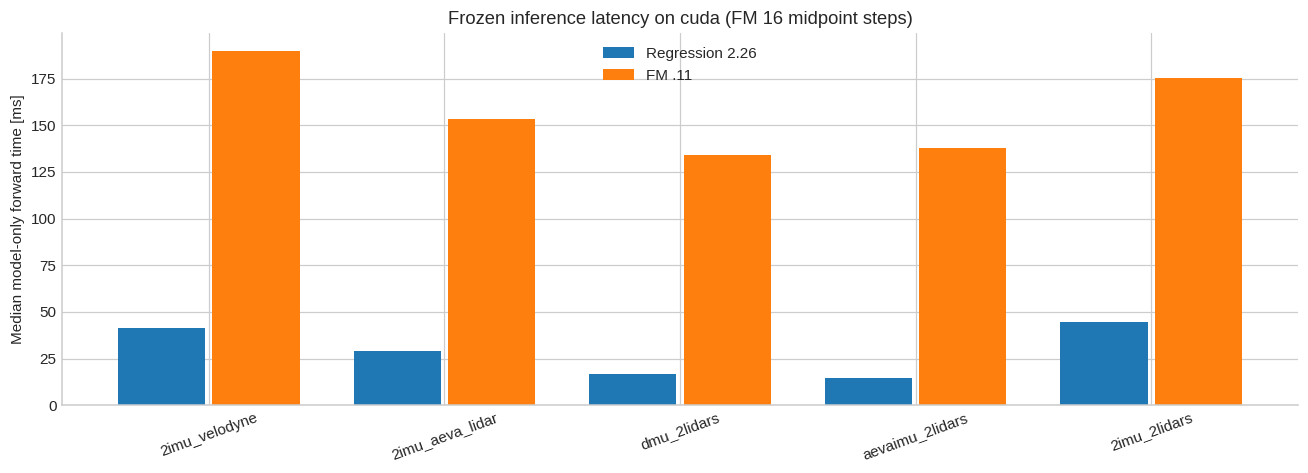

In [22]:
def sync_device():
    if DEVICE.type=="cuda":
        torch.cuda.synchronize(DEVICE)

@torch.inference_mode()
def profile_model_call(model,tokens,context):
    for _ in range(INFERENCE_BENCHMARK_WARMUP):
        predict_from_tokens(model,tokens,context)
    sync_device()
    measurements=[]
    for _ in range(INFERENCE_BENCHMARK_REPEATS):
        start=time.perf_counter()
        predict_from_tokens(model,tokens,context)
        sync_device()
        measurements.append((time.perf_counter()-start)*1000)
    return np.asarray(measurements)

latency_rows=[]
for topology in TOPOLOGIES:
    window=to_device(make_topology_window(first_full,topology))
    tokens,context=tokenize_candidate(window,window.current_calibration)
    for label,model in MODELS.items():
        vals=profile_model_call(model,tokens,context)
        latency_rows.append(dict(topology=topology,model=label,num_sensors=len(TOPOLOGIES[topology]),
                                 num_tokens=tokens.x.shape[1],parameters=sum(p.numel() for p in model.parameters()),
                                 median_latency_ms=np.median(vals),min_latency_ms=np.min(vals),
                                 max_latency_ms=np.max(vals)))
latency=pd.DataFrame(latency_rows)
display(latency.round(3))
if SAVE_RESULTS:
    latency.to_csv(OUT/"frozen_model_latency.csv",index=False)
fig,ax=plt.subplots(figsize=(12,4.4))
positions=np.arange(len(TOPOLOGIES))
for index,label in enumerate(MODEL_LABELS):
    values=latency[latency.model==label].set_index("topology").reindex(TOPOLOGIES).median_latency_ms
    ax.bar(positions + (.20 if index else -.20),values,width=.37,label=label)
ax.set(xticks=positions,xticklabels=list(TOPOLOGIES),ylabel="Median model-only forward time [ms]",
       title=f"Frozen inference latency on {DEVICE} (FM {FM_INTEGRATION_STEPS} {FM_INTEGRATION_METHOD} steps)")
ax.tick_params(axis="x",rotation=20)
ax.legend()
show_figure(fig,"09_frozen_model_latency.png")

## 17. Reproducibility manifest, interpretation and limits
What qualifies as generalization? Lower final error, sustained convergence, and no drift at 0° on a completely unseen physical dataset. Compare FM and regression using paired initial faults, physical windows and sensor keys. More input sensors need not help automatically: Velodyne and Aeva registration errors are different, and pooling may give an unreliable sensor too much influence. The 4-sensor model also receives a topology (four calibration heads) potentially outside the networks' training distribution.

Important limits:
1. Boreas calibration files are nominal spatial references, not independent high-precision extrinsic ground truth. The rotation scores are therefore nominal-reference errors.
2. Original Boreas LiDAR trajectory (sequence.lidar_poses) comes from Applanix/GNSS/INS; only ICP CSVs enter the network. Their scan-to-scan errors are real and may produce domain shift.
3. No independent temporal calibration labels are available. Absolute tau accuracy is not claimed.
4. A simultaneous common rotation of all sensor extrinsics is unobservable from relative sensor measurements alone. Pairwise relative rotations provide a useful gauge-invariant diagnostic; nominal absolute rotation errors are still useful for controlled injected-fault testing.
5. This notebook matches notebook 45's rotation-only update convention. Predicted translation components are not applied, because their frozen-head training/accuracy is not established by that reference experiment.
6. This is an evaluation-only notebook. It never updates weights or trains on Boreas.
The CSVs and PNG figures produced by the notebook are written to outputs/plots/<RUN_NAME>/. If a topology fails in the routing smoke test, treat it as an architecture compatibility finding, not as a numerical model failure.

In [23]:
manifest = {
    "experiment": RUN_NAME,
    "sequence": sequence.sequence_id,
    "boreas_root": str(sequence.root),
    "regression_checkpoint": str(REGRESSION_CHECKPOINT),
    "fm_checkpoint": str(FM_CHECKPOINT),
    "model_architecture": "same as NewCollege notebook 45; frozen regression 2.26 and FM .11",
    "fm_integration_steps": FM_INTEGRATION_STEPS,
    "fm_integration_method": FM_INTEGRATION_METHOD,
    "imu_inputs": ["dmu_infilled", "aeva"],
    "lidar_inputs": ["lidar_odometry_velodyne.csv", "lidar_odometry_aeva.csv"],
    "odometry_source": "independent scan registration, no Applanix input",
    "calibration_reference": "Boreas calib/T_*.txt in Applanix body frame",
    "clock_offsets_verified": False,
    "model_evaluated_timing_corrections_s": {"IMU":IMU_TIMESTAMP_SHIFTS_S,"LiDAR":LIDAR_TIMESTAMP_SHIFTS_S},
    "common_interval_utc_seconds": [COMMON_START_NS*1e-9,COMMON_END_NS*1e-9],
    "window_duration_s": WINDOW_DURATION_S,
    "window_stride_s": WINDOW_STRIDE_S,
    "valid_windows": len(boreas_windows),
    "rollout_window_indices": rollout_indices,
    "initial_rotation_angles_deg": ROTATION_ANGLES_DEG,
    "one_step_axes": ONE_STEP_AXES,
    "rollout_axes": ROLLOUT_AXES,
    "topologies": {name:list(keys) for name,keys in TOPOLOGIES.items()},
    "single_sensor_rollouts_run": RUN_SINGLE_SENSOR_ROLLOUTS,
    "whole_rig_rollouts_run": RUN_ALL_SENSOR_ROLLOUTS,
    "assumed_reference_tau_rollouts_run": RUN_ASSUMED_TAU_ROLLOUTS,
    "assumed_reference_mixed_rollouts_run": RUN_ASSUMED_MIXED_ROLLOUTS,
    "training_on_boreas": False,
}
if SAVE_RESULTS:
    (OUT/"experiment_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
print("Saved results to:",OUT if SAVE_RESULTS else "Saving disabled")
print("Evaluation complete. Inspect matched-four-vs-three deltas, per-sensor 0° stability and all-sensor pairwise errors before drawing a generalization conclusion.")

Saved results to: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/boreas_rt_fm11_vs_regression226_five_topologies
Evaluation complete. Inspect matched-four-vs-three deltas, per-sensor 0° stability and all-sensor pairwise errors before drawing a generalization conclusion.


## Appendix · Match notebook 04's successful Boreas experiment before interpreting the five-topology score
This appendix isolates the one-IMU + two-LiDAR, one-faulty-LiDAR, yaw-only experiment that appears successful in notebook 04. It uses the same two frozen checkpoints already loaded above, without changing their weights. These are diagnostic strata, not replacements for the more demanding X/Y, IMU, multi-topology, or whole-rig results.

Inputs may still differ from notebook 04: this notebook originally retains 550 IMU samples per 5-second window versus 700 in notebook 04. To match, set MAX_IMU_SAMPLES_PER_WINDOW = 700 in the first configuration cell and rerun from data construction. Also compare the printed UTC start times; notebook 03 requires four-sensor overlap even when evaluating its three-sensor topology, whereas notebook 04 requires the selected three sensors. Keep the overlap and indices identical for numerical parity.

The existing main notebook tests only the first and last windows for one-step plots and pools axes and sensor types in its summary. This appendix tests every selected window and reports axes and sensor types separately.

In [24]:
# A · Inspect what is being compared, then choose a matched three-sensor topology.
DIAG_TOPOLOGY = "dmu_2lidars"
DIAG_LIDAR_KEYS = tuple(k for k in TOPOLOGIES[DIAG_TOPOLOGY] if k.startswith("lidar_"))
DIAG_ANGLES_DEG = (0., 15., 45., 75., 90., 110., 130., 170.)
DIAG_MAX_WINDOWS = 30
DIAG_WINDOW_INDICES = list(range(min(len(boreas_windows), DIAG_MAX_WINDOWS)))

print("Matched topology:", DIAG_TOPOLOGY, DIAG_LIDAR_KEYS)
print("Samples/window cap:", MAX_IMU_SAMPLES_PER_WINDOW, "(notebook 04 used 700)")
print("Window duration/stride:", WINDOW_DURATION_S, WINDOW_STRIDE_S)
print("Selected windows:", len(DIAG_WINDOW_INDICES), "/", len(boreas_windows))
print("First / last physical start UTC [s]:", window_records[DIAG_WINDOW_INDICES[0]][0] * 1e-9,
      window_records[DIAG_WINDOW_INDICES[-1]][0] * 1e-9)
print("Checkpoint labels:", tuple(MODELS))


Matched topology: dmu_2lidars ('lidar_velodyne', 'lidar_aeva')
Samples/window cap: 700 (notebook 04 used 700)
Window duration/stride: 5.0 5.0
Selected windows: 30 / 35
First / last physical start UTC [s]: 1733248461.9910812 1733248606.9910812
Checkpoint labels: ('Regression 2.26', 'FM .11')


In [25]:
# B · Re-evaluate fresh-start one-step LiDAR YAW faults on every selected physical window.
#    Paired FM and regression calls use identical WindowBatch, reference states, and injected faults.
#    No topologies / axes / IMUs are pooled in the primary result.
diagnostic_rows = []
for i in tqdm(DIAG_WINDOW_INDICES, desc="All-window, yaw-only paired inference"):
    window = to_device(make_topology_window(boreas_windows[i], DIAG_TOPOLOGY))
    reference = window.current_calibration
    start_ns = int(window_records[i][0])
    for key in DIAG_LIDAR_KEYS:
        for angle in DIAG_ANGLES_DEG:
            initial = inject_fault(reference, key, (0., 0., angle))
            for label, model in MODELS.items():
                prediction = calibration_forward(window, initial, model)
                updated = apply_updates(initial, prediction, (key,), update_rotation=True, update_tau=False)
                initial_deg = errors_for(initial, reference, key)[0]
                final_deg = errors_for(updated, reference, key)[0]
                step_deg = float(torch.rad2deg(prediction.predictions[key].delta_xi[:, :3].norm(dim=-1))[0])
                diagnostic_rows.append(dict(topology=DIAG_TOPOLOGY, sensor=key, model=label,
                    window=i, start_ns=start_ns, relative_time_s=(start_ns-int(window_records[DIAG_WINDOW_INDICES[0]][0]))*1e-9,
                    axis="z", angle_deg=float(angle), initial_deg=initial_deg, final_deg=final_deg,
                    improvement_deg=initial_deg-final_deg, predicted_step_deg=step_deg))

diag_one_step = pd.DataFrame(diagnostic_rows)
diag_summary = diag_one_step.groupby(["sensor", "model", "angle_deg"],as_index=False).agg(
    median_improvement_deg=("improvement_deg","median"),
    p25_improvement_deg=("improvement_deg",lambda x: x.quantile(.25)),
    p75_improvement_deg=("improvement_deg",lambda x: x.quantile(.75)),
    median_final_deg=("final_deg","median"),
    improved_fraction=("improvement_deg",lambda x:(x>0).mean()),
    n=("improvement_deg","size"))
display(diag_summary.round(3))
if SAVE_RESULTS:
    diag_one_step.to_csv(OUT / "diagnostic_yaw_all_windows_paired_cases.csv",index=False)
    diag_summary.to_csv(OUT / "diagnostic_yaw_all_windows_summary.csv",index=False)


All-window, yaw-only paired inference:   0%|          | 0/30 [00:00<?, ?it/s]

,sensor,model,angle_deg,median_improvement_deg,p25_improvement_deg,p75_improvement_deg,median_final_deg,improved_fraction,n
0,lidar_aeva,FM .11,0.0,-2.182,-3.396,-1.262,2.182,0.000,30
1,lidar_aeva,FM .11,15.0,5.438,1.721,9.653,9.562,0.933,30
2,lidar_aeva,FM .11,45.0,7.180,1.397,25.701,37.820,0.900,30
3,lidar_aeva,FM .11,75.0,37.794,23.507,60.332,37.206,0.900,30
4,lidar_aeva,FM .11,90.0,65.067,42.665,75.582,24.933,0.900,30
5,lidar_aeva,FM .11,110.0,71.992,49.900,77.390,38.008,0.900,30
6,lidar_aeva,FM .11,130.0,62.165,40.022,69.069,67.835,0.900,30
7,lidar_aeva,FM .11,170.0,19.396,0.030,36.268,150.604,0.733,30
8,lidar_aeva,Regression 2.26,0.0,-1.589,-2.446,-0.432,1.589,0.000,30
9,lidar_aeva,Regression 2.26,15.0,3.992,0.990,8.279,11.008,0.933,30


/tmp/ipykernel_3402/707769399.py:86: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


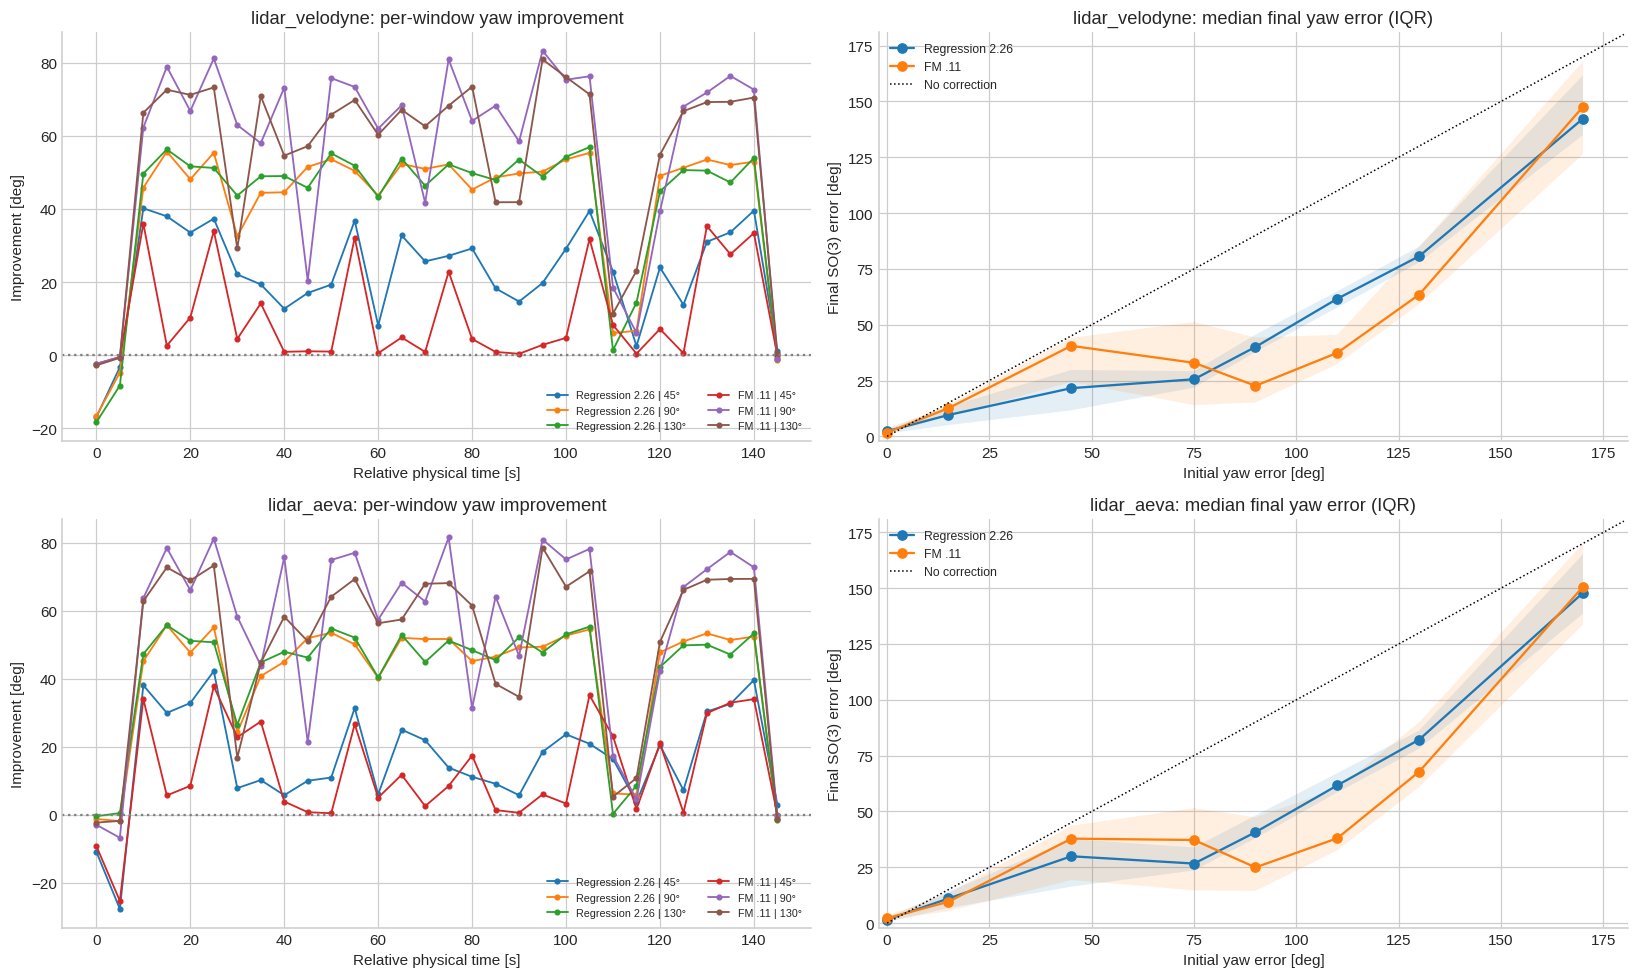

In [26]:
# C · Show fresh-start improvement per window and matched final-error-vs-initial curves.
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for j, key in enumerate(DIAG_LIDAR_KEYS):
    subset = diag_one_step[diag_one_step.sensor==key]
    for label in MODEL_LABELS:
        for angle in (45.,90.,130.):
            q=subset[(subset.model==label)&(subset.angle_deg==angle)].sort_values("window")
            axes[j,0].plot(q.relative_time_s, q.improvement_deg, marker=".", linewidth=1.2,
                           label=f"{label} | {angle:g}°")
        q=diag_summary[(diag_summary.sensor==key)&(diag_summary.model==label)].sort_values("angle_deg")
        axes[j,1].plot(q.angle_deg,q.median_final_deg,"-o",label=label)
        axes[j,1].fill_between(q.angle_deg,q.angle_deg-q.p75_improvement_deg,
                               q.angle_deg-q.p25_improvement_deg,alpha=.12)
    axes[j,0].axhline(0,color="gray",linestyle=":")
    axes[j,0].set(title=f"{key}: per-window yaw improvement",xlabel="Relative physical time [s]",ylabel="Improvement [deg]")
    axes[j,1].plot([0,180],[0,180],"k:",linewidth=1,label="No correction")
    axes[j,1].set(title=f"{key}: median final yaw error (IQR)",xlabel="Initial yaw error [deg]",ylabel="Final SO(3) error [deg]",xlim=(-2,181),ylim=(-2,181))
    axes[j,0].legend(fontsize=7,ncol=2);axes[j,1].legend(fontsize=8)
show_figure(fig,"diagnostic_yaw_all_windows_fm_vs_regression.png")


## D · Diagnose whether notebook 03's pooled result is dominated by other axes or sensors
The existing single_fault_rollouts data already contain per-sensor/per-axis chronological rollouts with identical initial errors for both models. Inspect the table below before saying that Boreas fails. The 0° case must be reported too: a model that corrects large faults but drifts away from a correct calibration is not reliably convergent. A 5° success threshold is stricter than a meaningful improvement from 90° to 15°; report both final error and improvement.

The "whole rig" plot tests a fundamentally different problem: simultaneous faults on multiple sensors, with different axes. Keep it as a separate robustness experiment.

,topology,sensor,axis,model,initial_angle_deg,final_deg,improvement_deg,within_10deg,within_20deg,stable_5deg
0,2imu_2lidars,lidar_aeva,x,FM .11,0.0,2.22,-2.22,1.0,1.0,1.0
1,2imu_2lidars,lidar_aeva,x,FM .11,15.0,2.01,12.99,1.0,1.0,1.0
2,2imu_2lidars,lidar_aeva,x,FM .11,45.0,14.70,30.30,0.0,1.0,0.0
3,2imu_2lidars,lidar_aeva,x,FM .11,90.0,80.06,9.94,0.0,0.0,0.0
4,2imu_2lidars,lidar_aeva,x,FM .11,130.0,151.41,-21.41,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
299,dmu_2lidars,lidar_velodyne,z,Regression 2.26,45.0,9.16,35.84,1.0,1.0,0.0
300,dmu_2lidars,lidar_velodyne,z,Regression 2.26,90.0,4.37,85.63,1.0,1.0,0.0
301,dmu_2lidars,lidar_velodyne,z,Regression 2.26,130.0,5.97,124.03,1.0,1.0,0.0
302,dmu_2lidars,lidar_velodyne,z,Regression 2.26,170.0,28.53,141.47,0.0,0.0,0.0


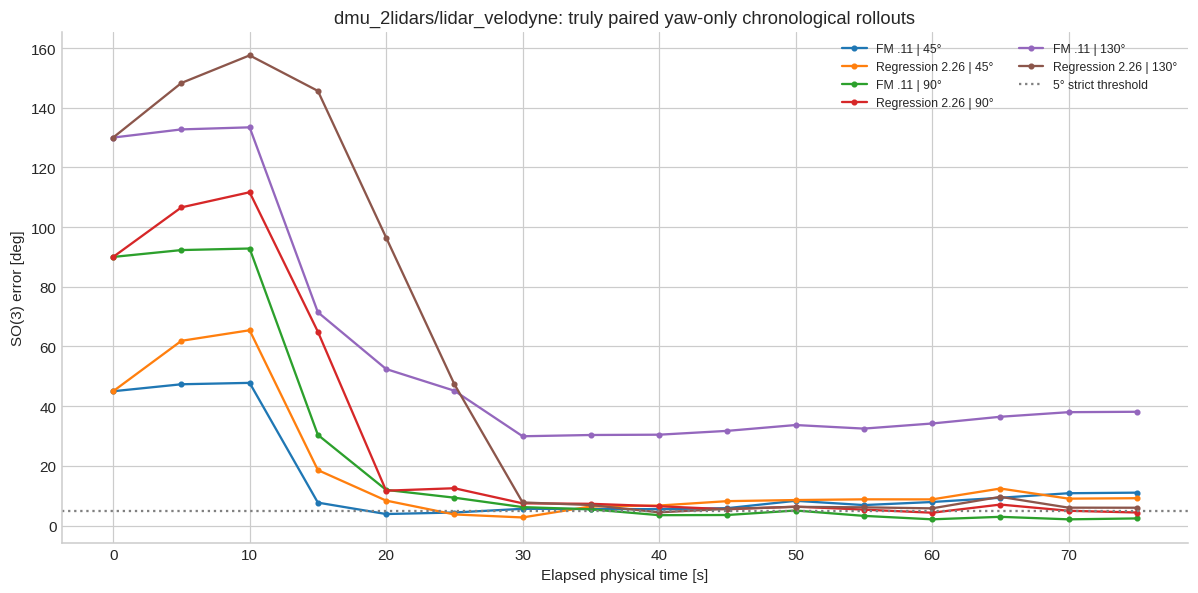

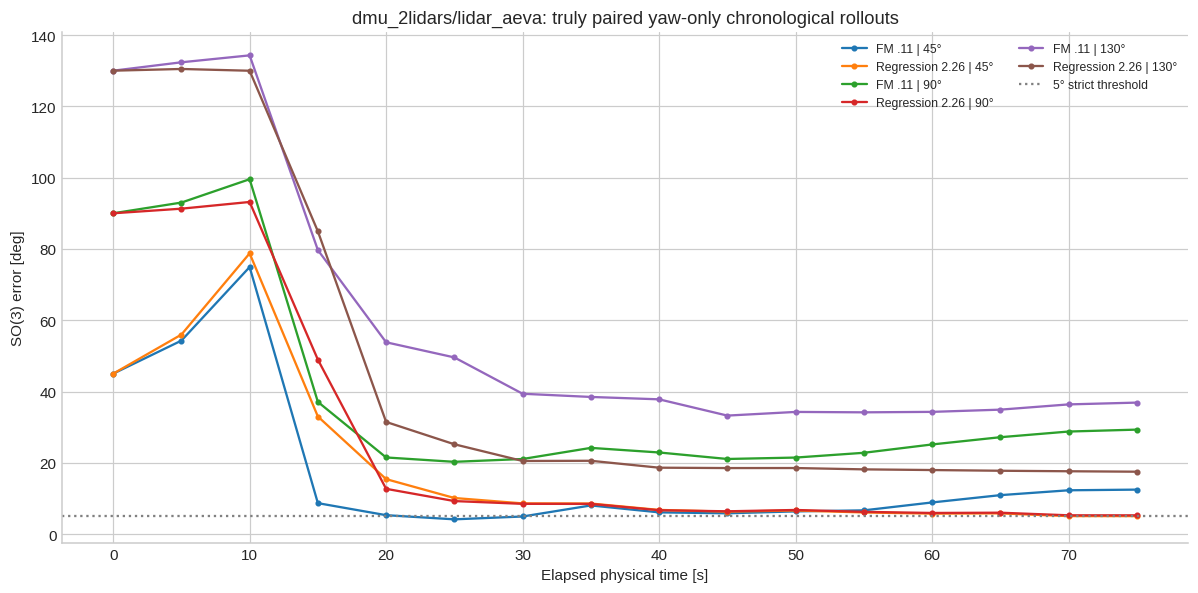

In [27]:
# D · Stratify existing chronological outcomes instead of pooling axes and sensor kinds.
if not single_summary.empty:
    stratified = single_summary[single_summary.sensor.str.startswith("lidar_")].copy()
    stratified["improvement_deg"] = stratified.initial_deg-stratified.final_deg
    stratified["within_10deg"] = stratified.final_deg < 10.
    stratified["within_20deg"] = stratified.final_deg < 20.
    display(stratified.groupby(["topology","sensor","axis","model","initial_angle_deg"],as_index=False)
        .agg(final_deg=("final_deg","median"), improvement_deg=("improvement_deg","median"),
             within_10deg=("within_10deg","mean"), within_20deg=("within_20deg","mean"),
             stable_5deg=("stable_convergence","mean")).round(2))
    if SAVE_RESULTS:
        stratified.to_csv(OUT/"diagnostic_lidar_axis_stratified_rollouts.csv",index=False)

    for key in DIAG_LIDAR_KEYS:
        subset = single_fault_rollouts[(single_fault_rollouts.topology==DIAG_TOPOLOGY)&
            (single_fault_rollouts.sensor==key)&(single_fault_rollouts.axis=="z")&
            (single_fault_rollouts.initial_angle_deg.isin([0.,45.,90.,130.]))]
        fig,ax=plt.subplots(figsize=(11,5.5))
        for (angle,label),group in subset.groupby(["initial_angle_deg","model"]):
            q=group.sort_values("step")
            ax.plot(q.elapsed_s,q.rotation_error_deg,marker=".",label=f"{label} | {angle:g}°")
        ax.axhline(5.,color="gray",linestyle=":",label="5° strict threshold")
        ax.set(title=f"{DIAG_TOPOLOGY}/{key}: truly paired yaw-only chronological rollouts",
               xlabel="Elapsed physical time [s]",ylabel="SO(3) error [deg]")
        ax.legend(fontsize=8,ncol=2)
        show_figure(fig,f"diagnostic_yaw_rollout_{key}.png")
